# B3 · Attention et Transformers : un mini-GPT from scratch — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b3_transformers/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B3.Q1 à B3.Q12, B3.R1 à B3.R3, B3.1 à B3.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B3.12 | causal_mask, padding_mask et scaled_dot_product_attention | 🔨 | ★★ | 30 |
|  | B3.13 | Prédire la carte d'attention quand une clé copie la requête, puis quand on retire la division par √d_k | 🔮 | ★ | 10 |
|  | B3.14 | split_heads, merge_heads et multi_head_attention | 🔨 | ★★★ | 45 |
|  | B3.15 | positional_encoding et apply_rope | 🔨 | ★★ | 30 |
|  | B3.16 | transformer_block en NumPy, validé contre nn.TransformerEncoderLayer | 🔨 | ★★★★ | 100 |
|  | B3.17 | Trois masques qui mentent : convention inversée, masque transposé, padding compté dans la loss | 🐛 | ★★ | 25 |
| B | B3.18 | De NumPy à PyTorch : un module CausalSelfAttention avec F.scaled_dot_product_attention | 📦 | ★★ | 30 |
|  | B3.19 | Mini-GPT caractère par caractère : embeddings de tokens et de positions, blocs pré-LN, tête liée | 📦 | ★★★ | 60 |
|  | B3.20 | Entraîner le mini-GPT sur Holmes : AdamW, warmup + cosinus, clipping, perplexité, face au LSTM du ch. 22 🚀 | 📦 | ★★★ | 60 |
| B | B3.21 à B3.30 | la suite du mini-GPT : courbes, Holmes amorcé en français, KV cache, cartes d'attention, ablations, BPE contre caractères, contexte long, ViT, test de causalité, défi (*prochaine étape de génération*) | | | |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main une attention par produit scalaire, avec et sans masque causal, et justifier la division par $\sqrt{d_k}$.
- Implémenter en NumPy les masques, l'attention multi-têtes, les encodages de position (sinusoïdal, RoPE) et un bloc Transformer pré-LN, et les valider contre PyTorch.
- Écrire et entraîner en PyTorch un mini-GPT sur Holmes, le faire générer avec un KV cache, et comparer sa perplexité à celle du LSTM du ch. 22.
- Estimer les paramètres, les FLOPs et la mémoire d'un Transformer, et mesurer le coût d'un long contexte.

**Rappel express.** $\operatorname{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \operatorname{softmax}\big(\mathbf{Q}\mathbf{K}^\top / \sqrt{d_k} + \mathbf{M}\big)\mathbf{V}$, la softmax sur les clés, $M_{ij} = -\infty$ là où le masque vaut `False`. Masque causal : la requête $i$ voit les clés $j \le i + S - L$. Multi-têtes : $(N, T, d) \to (N, H, T, d_h)$, $4d^2 + 4d$ paramètres. Encodage sinusoïdal : $PE_{p, 2i} = \sin(p\,\omega_i)$, $PE_{p, 2i+1} = \cos(p\,\omega_i)$, $\omega_i = 10000^{-2i/d}$. RoPE : $\langle R_{m\theta} \mathbf{q}, R_{n\theta} \mathbf{k} \rangle = \langle \mathbf{q}, R_{(n-m)\theta} \mathbf{k} \rangle$. Bloc pré-LN : $\mathbf{h} = \mathbf{x} + \operatorname{MHA}(\operatorname{LN}_1(\mathbf{x}))$, $\mathbf{y} = \mathbf{h} + \operatorname{MLP}(\operatorname{LN}_2(\mathbf{h}))$, environ $12d^2$ paramètres. Entraînement : environ $6ND$ FLOPs ; KV cache : $2 \times L \times T \times d \times$ octets par valeur.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B3.1 à B3.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme de tableau : entre guillemets (`"(2, 3)"`) ; un vecteur ou une ligne de matrice : une liste (`[0.5, -1, 3]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ B3.6 et B3.7, l'estimation 🧮 B3.8, la réflexion (🗣️ B3.9, ⚖️ B3.10, 📄 B3.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np


def softmax_rows(s):
    """Stable softmax over the last axis (the keys); -inf gives a weight of exactly 0."""
    s = np.asarray(s, dtype=float)
    e = np.exp(s - s.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


# ✏️ B3.1: three tokens, d_k = 2 (token i is row i), no mask
X_B31 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
WQ_B31 = np.array([[0.0, 1.0], [1.0, 1.0]])
WK_B31 = np.array([[1.0, 0.0], [1.0, 2.0]])
WV_B31 = np.array([[1.0, -1.0], [0.0, 2.0]])
Q_B31, K_B31, V_B31 = X_B31 @ WQ_B31, X_B31 @ WK_B31, X_B31 @ WV_B31
RAW_B31 = Q_B31 @ K_B31.T                                           # (L, S) dot products
S_B31 = RAW_B31 / math.sqrt(2)                                      # scaled scores
A_B31 = softmax_rows(S_B31)                                         # attention map, softmax over the keys
O_B31 = A_B31 @ V_B31
A_NOSCALE_B31 = softmax_rows(RAW_B31)
A_COLUMNS_B31 = softmax_rows(S_B31.T).T                             # the classic mistake: softmax over the queries

# ✏️ B3.2: the same with a causal mask, then L = 2 new queries against S = 3 keys (KV cache)
CAUSAL_B32 = np.tril(np.ones((3, 3), dtype=bool))
TRIU_B32 = np.triu(np.ones((3, 3), dtype=bool))                     # the transposed mask of 🐛 B3.17
A_C_B32 = softmax_rows(np.where(CAUSAL_B32, S_B31, -np.inf))
O_C_B32 = A_C_B32 @ V_B31
A_ZERO_B32 = np.where(CAUSAL_B32, A_B31, 0.0)                       # the classic mistake: zeroed, not renormalized
A_NOSCALE_C_B32 = softmax_rows(np.where(CAUSAL_B32, RAW_B31, -np.inf))
A_TRIU_B32 = softmax_rows(np.where(TRIU_B32, S_B31, -np.inf))
BOTTOM_RIGHT_B32 = np.tril(np.ones((2, 3), dtype=bool), k=1)        # causal_mask(2, 3)
TOP_LEFT_B32 = np.tril(np.ones((2, 3), dtype=bool), k=0)            # is_causal=True of SDPA when L != S

# ✏️ B3.3: shapes and parameters of a multi-head attention
N_B33, T_B33, D_B33, H_B33, S_B33, HKV_B33 = 4, 10, 384, 6, 25, 2
DH_B33 = D_B33 // H_B33
MHA_B33 = 4 * D_B33 ** 2 + 4 * D_B33
GQA_B33 = 2 * (D_B33 * D_B33 + D_B33) + 2 * (D_B33 * HKV_B33 * DH_B33 + HKV_B33 * DH_B33)

# ✏️ B3.4: sinusoidal encoding, d = 8 (angular frequencies 1, 0.1, 0.01, 0.001)
D_B34 = 8
OMEGA_B34 = 10000.0 ** (-np.arange(0, D_B34, 2) / D_B34)


def pe_b34(p, omega=OMEGA_B34):
    """Row p of the sinusoidal encoding: sin in the even columns, cos in the odd ones."""
    row = np.zeros(2 * len(omega))
    row[0::2], row[1::2] = np.sin(p * omega), np.cos(p * omega)
    return row


PAIR_B34 = np.array([0.6, 0.8])                                     # (PE[p, 2], PE[p, 3]) for some real position p


def shift_b34(pair, angle):
    """The shift matrix of the fiche (203.5) applied to a (sin, cos) pair; a negative angle shifts backwards."""
    return np.array([[math.cos(angle), math.sin(angle)], [-math.sin(angle), math.cos(angle)]]) @ pair


SHIFT_B34 = shift_b34(PAIR_B34, 10 * OMEGA_B34[1])                  # 10 positions on pair 1: 1 radian
PE_DOT_B34 = float(pe_b34(0) @ pe_b34(2))


# ✏️ B3.5: GPT-2 small (config.json of openai-community/gpt2) and the mini-GPT of the notebook
def gpt_params(n_layer, d, vocab, n_pos, tied=True):
    """Parameters of a GPT-2-style decoder: biases everywhere, F = 4d, learned positions, final layer norm."""
    attn, mlp, lns = 4 * d * d + 4 * d, 8 * d * d + 5 * d, 4 * d
    block = attn + mlp + lns
    return {"attn": attn, "mlp": mlp, "block": block, "blocks": n_layer * block, "wte": vocab * d,
            "wpe": n_pos * d, "ln_f": 2 * d,
            "total": n_layer * block + vocab * d * (1 if tied else 2) + n_pos * d + 2 * d,
            "non_embedding": n_layer * block + 2 * d}


GPT2_B35 = gpt_params(12, 768, 50257, 1024)
GPT2_UNTIED_B35 = gpt_params(12, 768, 50257, 1024, tied=False)["total"]
MINI_B35 = gpt_params(4, 128, 88, 128)
PAPER_B35 = 117e6                                                   # table 2 of the GPT-2 paper ("117M")

# quizzes and recalls with a computation
Q2C = (1 * 2 + 3 * 2) / math.sqrt(2)                                # q = (1, 3), k = (2, 2), d_k = 2
Q2D = 3 / (1 + 1 + 3)                                               # scores (0, 0, ln 3): exponentials 1, 1, 3
Q7E = 250 * 10000.0 ** (-2 * 16 / 64)                               # pair i = 16 of d_h = 64, position 250
Q8D = 2 * 512 * 2048 + 2048 + 512
Q11E = 2 * 2 * 100 * 64 * 4                                         # 2 (K and V) x layers x tokens x d x bytes
Q10E = math.log(65)
X_R3 = np.array([1.0, 2.0, 3.0, 6.0])
LN_R3 = (X_R3 - X_R3.mean()) / X_R3.std()                           # biased variance, as in your layer_norm

# The same answers from the libraries (no download): mylearn (reference), PyTorch, transformers
import torch
import torch.nn.functional as F
from torch import nn

A = mylearn.attention
# ✏️ B3.1 and B3.2: scaled_dot_product_attention of the reference and of PyTorch, with and without the masks
out, w = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31)
assert np.allclose(w, A_B31) and np.allclose(out, O_B31)
tq, tk, tv = (torch.tensor(a) for a in (Q_B31, K_B31, V_B31))
assert np.allclose(F.scaled_dot_product_attention(tq, tk, tv).numpy(), O_B31)
assert np.allclose(A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, scale=1.0)[1], A_NOSCALE_B31)
assert np.array_equal(A.causal_mask(3), CAUSAL_B32) and int(A.causal_mask(3).sum()) == 6
out_c, w_c = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, mask=A.causal_mask(3))
assert np.allclose(w_c, A_C_B32) and np.allclose(out_c, O_C_B32)
assert np.allclose(F.scaled_dot_product_attention(tq, tk, tv, is_causal=True).numpy(), O_C_B32)
assert np.array_equal(A.causal_mask(2, 3), BOTTOM_RIGHT_B32)
cache_out, _ = A.scaled_dot_product_attention(Q_B31[1:], K_B31, V_B31, mask=A.causal_mask(2, 3))
assert np.allclose(cache_out, O_C_B32[1:])                          # the KV cache gives rows 1 and 2 of the full run
top_left = F.scaled_dot_product_attention(tq[1:], tk, tv, is_causal=True).numpy()
assert not np.allclose(top_left, O_C_B32[1:])
assert np.allclose(top_left[0], tv[0].numpy())                      # the first new query sees only key 0
from torch.nn.attention.bias import causal_lower_right
assert np.allclose(F.scaled_dot_product_attention(tq[1:], tk, tv, attn_mask=causal_lower_right(2, 3)).numpy(),
                   O_C_B32[1:])
w_triu = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, mask=TRIU_B32)[1]
assert w_triu[2, 0] == 0 and w_triu[2, 1] == 0 and np.all(w_triu[0] > 0)

# ✏️ B3.3: nn.MultiheadAttention, split_heads and multi_head_attention of the reference, GQA with nn.Linear
mha = nn.MultiheadAttention(D_B33, H_B33)
assert sum(p.numel() for p in mha.parameters()) == MHA_B33 and tuple(mha.in_proj_weight.shape) == (3 * D_B33, D_B33)
mha12 = nn.MultiheadAttention(D_B33, 12)
assert sum(p.numel() for p in mha12.parameters()) == MHA_B33
rng = np.random.default_rng(0)
params = {f"W_{c}": rng.normal(size=(D_B33, D_B33)) / 20 for c in "qkvo"} | {f"b_{c}": np.zeros(D_B33) for c in "qkvo"}
x = rng.normal(size=(N_B33, T_B33, D_B33))
assert A.split_heads(x @ params["W_q"], H_B33).shape == (N_B33, H_B33, T_B33, DH_B33)
o, w = A.multi_head_attention(x, x, x, params, n_heads=H_B33)
assert o.shape == (N_B33, T_B33, D_B33) and w.shape == (N_B33, H_B33, T_B33, T_B33) and w.size == 2400
enc = rng.normal(size=(N_B33, S_B33, D_B33))
assert A.multi_head_attention(x, enc, enc, params, n_heads=H_B33)[1].shape == (N_B33, H_B33, T_B33, S_B33)
gqa = nn.ModuleList([nn.Linear(D_B33, D_B33), nn.Linear(D_B33, HKV_B33 * DH_B33), nn.Linear(D_B33, HKV_B33 * DH_B33),
                     nn.Linear(D_B33, D_B33)])
assert sum(p.numel() for p in gqa.parameters()) == GQA_B33

# ✏️ B3.4: positional_encoding of the reference; the shift matrix on real positions and on integer ones
PE = A.positional_encoding(200, D_B34)
assert np.allclose(PE[25], pe_b34(25)) and np.isclose(PE[0] @ PE[2], PE_DOT_B34) and np.isclose(PE[100] @ PE[102], PE_DOT_B34)
p_real = math.asin(0.6) / OMEGA_B34[1]                               # the position of the statement, about 6.4
assert np.allclose(pe_b34(p_real)[2:4], PAIR_B34) and np.allclose(pe_b34(p_real + 10)[2:4], SHIFT_B34)
for p in (0, 7, 33):
    assert np.allclose(shift_b34(PE[p, 2:4], 10 * OMEGA_B34[1]), PE[p + 10, 2:4])
assert round(2 * math.pi / OMEGA_B34[2]) == 628

# ✏️ B3.5: GPT-2 small and the mini-GPT, built without their weights (meta device)
import warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)
from transformers import GPT2Config, GPT2LMHeadModel
with torch.device("meta"):
    gpt2 = GPT2LMHeadModel(GPT2Config())
    gpt2_untied = GPT2LMHeadModel(GPT2Config(tie_word_embeddings=False))
    mini = GPT2LMHeadModel(GPT2Config(n_layer=4, n_head=4, n_embd=128, n_positions=128, vocab_size=88,
                                       bos_token_id=0, eos_token_id=0))
count = lambda model: sum(p.numel() for p in model.parameters())   # noqa: E731
assert count(gpt2) == GPT2_B35["total"] and count(gpt2_untied) == GPT2_UNTIED_B35 and count(mini) == MINI_B35["total"]
assert count(gpt2.transformer.h[0]) == GPT2_B35["block"] and count(gpt2.transformer.h[0].attn) == GPT2_B35["attn"]
assert count(gpt2.transformer.h[0].mlp) == GPT2_B35["mlp"]
assert count(gpt2) - count(gpt2.transformer.wte) - count(gpt2.transformer.wpe) == GPT2_B35["non_embedding"]
block = nn.TransformerEncoderLayer(768, 12, 3072, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
assert count(block) == GPT2_B35["block"]

# quizzes and recalls with a computation
qa = torch.tensor([[1.0, 3.0]])
assert np.isclose((qa @ torch.tensor([[2.0], [2.0]])).item() / math.sqrt(2), Q2C)
assert np.isclose(torch.softmax(torch.tensor([0.0, 0.0, math.log(3)]), 0)[2].item(), Q2D)
assert int(A.causal_mask(5).sum()) == 15 and int(A.causal_mask(1, 9).sum()) == 9
angles = np.arange(251)[:, None] * 10000.0 ** (-2 * np.arange(32) / 64)
assert np.isclose(angles[250, 16], Q7E)
assert count(nn.Sequential(nn.Linear(512, 2048), nn.GELU(), nn.Linear(2048, 512))) == Q8D
assert count(nn.LayerNorm(1600)) == 3200 and count(nn.LayerNorm(768)) == 1536
assert np.allclose(mylearn.nn.regularization.layer_norm(X_R3[None], eps=0.0)[0], LN_R3)
assert np.allclose(F.layer_norm(torch.tensor(X_R3), (4,), eps=0.0).numpy(), LN_R3)
print("✅ the paper answers agree with mylearn (reference), PyTorch and transformers")

✅ the paper answers agree with mylearn (reference), PyTorch and transformers


**B3.Q1 — Le goulot de l'encodeur-décodeur récurrent : pourquoi un seul vecteur ne suffit pas**

In [3]:
wb.record("B3.Q1a", "C", mistakes={"relis « Traduire avec deux RNN » (§203.1) : le décodeur de 2014 relit-il la source ?": "A", "relis « Traduire avec deux RNN » : par où passent les mots source ?": "B"})
wb.record("B3.Q1b", False, mistakes={"relis « Le goulot » (§203.1) : la taille de c dépend-elle de la phrase ?": True})
wb.record("B3.Q1c", 12 * 9, mistakes={"relis la question : on demande les poids de tous les pas de la traduction": 12,
          "relis la question : on demande les poids de tous les mots source, à chaque pas": 9,
          "tu as additionné : combien de poids à chaque pas, et combien de pas ?": 21})
wb.record("B3.Q1d", "A", mistakes={"relis l'étape 2 de l'idée de Bahdanau : sur quoi porte la softmax ?": "B", "relis le paragraphe qui suit les quatre étapes : l'alignement est-il un choix d'un seul mot ?": "C"})
wb.record("B3.Q1e", True, mistakes={"relis le paragraphe sur l'alignement souple (§203.1) : d'où viennent les poids ?": False})

WB_ANSWER {"hash": "365b1b487e54aca5cf2c3ec7bc0fae05ebf0de2f731ec8c9b5277f1b687ee8fd", "id": "B3.Q1a", "kind": "str", "mistakes": {"73a1c1f10cea604ed92b2ccd475ccb2920f1c345de1ff61e3900ffe211589bd2": "relis « Traduire avec deux RNN » (§203.1) : le décodeur de 2014 relit-il la source ?", "ab54e0550ba97f4b41c5c3ad3ba98e018daeee768648ee2c171e8e800ab88fa6": "relis « Traduire avec deux RNN » : par où passent les mots source ?"}}
📝 Ex B3.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "3ddb75edcdb8230c49075e913c00f55d67248a78f57785530bd2516bfe551721", "id": "B3.Q1b", "kind": "bool", "mistakes": {"e119f29c4617b276bfc9116f17be9860ace156ddb4b5bebc18d1af1fe6641f51": "relis « Le goulot » (§203.1) : la taille de c dépend-elle de la phrase ?"}}
📝 Ex B3.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "d7abf0f2beea0c6bdbd61d5d335d6e932817b6f0c74b0231d587c0069aa4ed42", "id": "B3.Q1c", "kind": "int", "magnitude": 2, "mistakes": {"3520c9151bbc2628edb0ab185bd321076e616a8db8a4b8b76659192240a92d8e"

**B3.Q2 — Requête, clé, valeur : un dictionnaire où l'on cherche « à peu près »**

In [4]:
wb.record("B3.Q2a", "B", mistakes={"relis « Un dictionnaire où l'on cherche à peu près » : rend-on une seule valeur ?": "A", "relis le rôle de chaque vecteur : qu'est-ce que l'attention rend ?": "C"})
wb.record("B3.Q2b", False, mistakes={"relis « D'où viennent les requêtes, les clés et les valeurs » : combien de projections ?": True})
wb.record("B3.Q2c", Q2C, decimals=2, mistakes={"relis la question : le score est mis à l'échelle": 8.0,
          "on divise par la racine de d_k, pas par d_k": 4.0})
wb.record("B3.Q2d", Q2D, decimals=1, mistakes={"les scores passent par l'exponentielle avant d'être normalisés": 1.0,
          "compare les exponentielles des trois scores : sont-elles égales ?": 1 / 3})
wb.record("B3.Q2e", "C", mistakes={"c'est la forme des poids de la requête : on demande sa sortie": "A", "relis l'étape 5 de « La formule » : que devient la somme pondérée ?": "B"})

WB_ANSWER {"hash": "0c500beff3803fa26539287e6c1e91c08d5f9ab6ea877d80e92538792eb0a92e", "id": "B3.Q2a", "kind": "str", "mistakes": {"0c7dcacc226a8306ec9ddc885687313b2fc4cb7b058fc393bf2e3310eb616f6c": "relis le rôle de chaque vecteur : qu'est-ce que l'attention rend ?", "f1abd6fb46cae9266e705c0b27fb12e566f01efad966569ed890ed12cc923977": "relis « Un dictionnaire où l'on cherche à peu près » : rend-on une seule valeur ?"}}
📝 Ex B3.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "9051f17cd9b1015c4874125fa0ee1c4764ba6e65241f1bc07f117d69be112246", "id": "B3.Q2b", "kind": "bool", "mistakes": {"e5f4dc3f52a51f62c09dbb8b6e946a92137a30742b93fb03d059872fe970021a": "relis « D'où viennent les requêtes, les clés et les valeurs » : combien de projections ?"}}
📝 Ex B3.Q2b : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "f26ae514c28003ce5ab7eefb4873784df5350367135e8bfda01369fc153dadd6", "hash_coarse": "fddf848b8542f0dc54759a104ed9de7ff76234fe782cb0eecca001881399c872", "id": "B3.Q2c", 

**B3.Q3 — Pourquoi diviser les scores par √d_k ?**

In [5]:
wb.record("B3.Q3a", math.isqrt(256), mistakes={"c'est la variance : on demande l'écart-type": 256,
          "relis la question : d_k = 256": 8})
wb.record("B3.Q3b", True, mistakes={"relis « Pourquoi diviser par √d_k » : que vaut Var(aX) avec a = 1/√d_k ?": False})
wb.record("B3.Q3c", "A", mistakes={"relis le paragraphe sur la softmax saturée : quel poids prend le plus grand score ?": "B", "une softmax peut-elle donner un poids négatif ?": "C"})
wb.record("B3.Q3d", "C", mistakes={"l'échelle des scores compte avant l'exponentielle : relis l'effet de la variance des scores sur la softmax": "A", "diviser par plus que √d_k rend-il les scores plus grands ou plus petits ?": "B"})
wb.record("B3.Q3e", False, mistakes={"relis l'argument de la variance : de quels vecteurs le score est-il fait ?": True})

WB_ANSWER {"hash": "6c07c88d0007fa223235aa6b22cd53da8d94c8d109eae2ffa324494aa5ae5f86", "id": "B3.Q3a", "kind": "int", "magnitude": 1, "mistakes": {"9b3df75729c4f5d12a65ac1d8f2c6e0a45d199a0e7053b55b65615c4133a79b7": "c'est la variance : on demande l'écart-type", "a505cbfc6f6ee5372ac36e5bcaece471babc939fce04680c884d4daf4146ddf0": "relis la question : d_k = 256"}, "sign": 1}
📝 Ex B3.Q3a : réponse enregistrée (int).
WB_ANSWER {"hash": "97581c1b33d227f0e9dff24b0710a1c0fc68cc3f08ebb7b4ef6cd82aa12b2abd", "id": "B3.Q3b", "kind": "bool", "mistakes": {"eba65c48755501f1709c0051506a3c676e12fdfbd77cc04f7f38d443badccf75": "relis « Pourquoi diviser par √d_k » : que vaut Var(aX) avec a = 1/√d_k ?"}}
📝 Ex B3.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "eb84077f9b5e6608b379967715ce57e59c1f8816a13abc76db6b4b7776a3247e", "id": "B3.Q3c", "kind": "str", "mistakes": {"56c793590693963ba77efd1ad305753c560b374ae1fa5add32abcffbb0973ee1": "relis le paragraphe sur la softmax saturée : quel poids prend le 

**B3.Q4 — Masque causal : qui a le droit de regarder qui ?**

In [6]:
wb.record("B3.Q4a", int(np.tril(np.ones((5, 5))).sum()), mistakes={"compte à nouveau : la diagonale est-elle autorisée ?": 10,
          "le masque causal interdit des cases : lesquelles ?": 25,
          "compte toutes les cases vraies, pas seulement la diagonale": 5})
wb.record("B3.Q4b", "B", mistakes={"relis la phrase sous la formule du masque causal : combien de cases vraies a la ligne i ?": "A", "le masque causal cache-t-il le futur ou le passé ?": "C"})
wb.record("B3.Q4c", False, mistakes={"relis la conséquence utile du masque causal (§203.3)": True})
wb.record("B3.Q4d", 9, mistakes={"c'est l'alignement en haut à gauche de is_causal=True : relis celui de causal_mask": 1,
          "la dernière requête voit-elle sa propre clé ?": 8})
wb.record("B3.Q4e", "A", mistakes={"c'est le rôle d'un autre masque : relis « Le masque de padding »": "B", "relis le rôle du masque : change-t-il le nombre de scores calculés ?": "C"})

WB_ANSWER {"hash": "9839be5b6a783fdfda4cce2b4bbb6d4b922ef80bcb067f81d845060b8e1cda6a", "id": "B3.Q4a", "kind": "int", "magnitude": 1, "mistakes": {"3132e5ebc19f1e886f799451824770cd8835f11da34f9a0611eceef7fe927950": "compte toutes les cases vraies, pas seulement la diagonale", "60a96eed531c481cbe67659c148668f1ed19b73ab9f2c0cc744e55d1194e033d": "compte à nouveau : la diagonale est-elle autorisée ?", "9689744674a37c1e5f9a3281aa00e3729eb459592225f6971fd8f6d37532a12c": "le masque causal interdit des cases : lesquelles ?"}, "sign": 1}
📝 Ex B3.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "666cd8f9db6676a3965e4431926db963468fb9b72d2ca40aff154b85b85583e4", "id": "B3.Q4b", "kind": "str", "mistakes": {"ad1f60da5fe4aa189a33b9591b9ffa0fadaef1601dda2c62fef683f006347832": "le masque causal cache-t-il le futur ou le passé ?", "c8cf0d076c34609364dc3000efacaf238350cb5a46166fdc0c022d1f6eea9a16": "relis la phrase sous la formule du masque causal : combien de cases vraies a la ligne i ?"}}
📝 Ex B3.Q

**B3.Q5 — Auto-attention ou attention croisée : d'où viennent Q, K et V ?**

In [7]:
wb.record("B3.Q5a", "A", mistakes={"relis la formule de l'attention croisée (§203.3) : d'où vient Q ?": "B", "relis « Auto-attention et attention croisée » : les clés et les requêtes viennent-elles de la même séquence ?": "C"})
wb.record("B3.Q5b", "(7, 12)", mistakes={"relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?": "(12, 7)",
          "les clés viennent de la source : combien de colonnes ?": "(7, 7)",
          "les requêtes viennent de la traduction : combien de lignes ?": "(12, 12)"})
wb.record("B3.Q5c", False, mistakes={"relis le tableau des familles (§203.7) : quel masque dans l'attention croisée ?": True})
wb.record("B3.Q5d", "C", mistakes={"les trois arguments ne sont pas les mêmes : relis l'ordre query, key, value": "A", "le premier argument fournit les requêtes : qui regarde qui ?": "B"})
wb.record("B3.Q5e", True, mistakes={"relis la définition de l'auto-attention (§203.3)": False})

WB_ANSWER {"hash": "440d71bb2da4e81d2c7e5528f0c5044a0048deff4a2626128415941f2f00ce1a", "id": "B3.Q5a", "kind": "str", "mistakes": {"44ca82a3c672efec6fc3ee954fe600944f01f6e81a14b980460ed8d6063e8ca2": "relis la formule de l'attention croisée (§203.3) : d'où vient Q ?", "e4551531ecc70971092580185f905aba096d1298034acd012d97110e46ef6c4b": "relis « Auto-attention et attention croisée » : les clés et les requêtes viennent-elles de la même séquence ?"}}
📝 Ex B3.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "c914bea10f90373a4066bc7124c71826035e7ade23fe52dc8c50795f3aab9ea8", "id": "B3.Q5b", "kind": "str", "mistakes": {"1818a5b05f9916ad76df432839fdc340ded42e06848eceb33b639925d6fdf5c4": "les clés viennent de la source : combien de colonnes ?", "481632a6d89e4d618fffa66d61df9a35455d8e65bcd6650c8f03b2d40a156b24": "relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?", "b41a95a606f4efe97e504da65547154c1c1d193c12182e66975daba6755cc7b8": "les requêtes viennent de la tr

**B3.Q6 — Plusieurs têtes pour le prix d'une : que gagne-t-on ?**

In [8]:
wb.record("B3.Q6a", 512 // 16, mistakes={"tu as multiplié : relis la définition de d_h": 8192,
          "recompte avec H = 16": 64})
wb.record("B3.Q6b", False, mistakes={"relis « Compter les paramètres » (§203.4)": True})
wb.record("B3.Q6c", 32 // 4, mistakes={"c'est le nombre de têtes de clés : on demande un rapport": 4,
          "on demande un rapport, pas une différence": 28,
          "on demande un rapport, pas un produit": 128})
wb.record("B3.Q6d", "A", mistakes={"relis le piège classique « un reshape direct » : y a-t-il une erreur ?": "B", "relis le piège classique « un reshape direct » : quelle tête reçoit quelles features ?": "C"})
wb.record("B3.Q6e", True, mistakes={"relis le paragraphe sur repeat_interleave (§203.4), et écris les deux ordres de têtes": False})

WB_ANSWER {"hash": "e4ed72b7f58fa2743f617ec39a1ed0783ef3c3091ac8fb7e6f32bf7e603d3ce5", "id": "B3.Q6a", "kind": "int", "magnitude": 1, "mistakes": {"c2957c0ba0bb9350221b537703d8fbcaa63fb277017e37ee08465487b8e27964": "tu as multiplié : relis la définition de d_h", "d061fe56da40a9e284464b94cff329cc03755d204e87a3715bfaadb3de9f7158": "recompte avec H = 16"}, "sign": 1}
📝 Ex B3.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "d2fdd9346b278420f6e8ec6c8d2ee46c010b799c0f138ad5ff1b253838a2f308", "id": "B3.Q6b", "kind": "bool", "mistakes": {"9518d6e5e731728c0b299e5daa5f5b8f1cb17036cc36e128a20fa97b834b682e": "relis « Compter les paramètres » (§203.4)"}}
📝 Ex B3.Q6b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0056816709584d98862e499677824a6d63aed536c242aa3146ece728c81d6d06", "id": "B3.Q6c", "kind": "int", "magnitude": 0, "mistakes": {"009c83cc2be8d0241958e747a9e18d39a315264f2f189afbffd0a784e65c78af": "on demande un rapport, pas une différence", "1b633a9f60ee41d34a8b5d299ec89a0f1a1762779ae

**B3.Q7 — Sans encodage de position, l'attention voit-elle l'ordre des mots ?**

In [9]:
wb.record("B3.Q7a", True, mistakes={"relis « L'attention ne voit pas l'ordre » (§203.5)": False})
wb.record("B3.Q7b", "A", mistakes={"sans position, l'attention sait-elle qui est voisin de qui ?": "B", "la sortie est une moyenne de valeurs : pourquoi serait-elle nulle ?": "C"})
wb.record("B3.Q7c", "B", mistakes={"relis « Les positions apprises » : quelle est la limite de la table ?": "A", "relis « Les positions apprises » : la table a-t-elle une règle pour les positions trop grandes ?": "C"})
wb.record("B3.Q7d", "C", mistakes={"relis le premier paragraphe de « RoPE » : touche-t-il aux embeddings ?": "A", "relis les trois points pratiques de RoPE : quels vecteurs sont tournés ?": "B"})
wb.record("B3.Q7e", Q7E, decimals=1, mistakes={"vérifie l'exposant de la fréquence θ_i (fiche, « RoPE »)": 250 * 10000.0 ** (-16 / 64),
          "relis la question : la paire i = 16, pas la paire 0": 250.0,
          "on demande des radians, pas des degrés": math.degrees(Q7E)})

WB_ANSWER {"hash": "0182f00325cca3fdf5a6f5fce5c8b5f550b49e90548e713bcabed6c729c3394a", "id": "B3.Q7a", "kind": "bool", "mistakes": {"3c65f6e11e3bb55e6464779c0ba82458e517bcfb45e05d9adb3fa88080688c42": "relis « L'attention ne voit pas l'ordre » (§203.5)"}}
📝 Ex B3.Q7a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f059562f81f7cf23e2da88c3da194075a8f73a23444cc07d8fc427bb361bb0d5", "id": "B3.Q7b", "kind": "str", "mistakes": {"0626fe81c32836a84500c5e0465cac18b2e0c12d375abe415c2d5d87ee7e72b1": "la sortie est une moyenne de valeurs : pourquoi serait-elle nulle ?", "11e09065927cd826c5b795fe514e6d592944788e740efc99fe3306a674fd4a74": "sans position, l'attention sait-elle qui est voisin de qui ?"}}
📝 Ex B3.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "f75e68ac8a038364eb058bad47ed1475e165f0f64100a5171e28aa58d56edbb6", "id": "B3.Q7c", "kind": "str", "mistakes": {"12b2b18e45787106b73c05a2fdb04ca4a53d818e6ab29632b7a05545192eae66": "relis « Les positions apprises » : la table a-t-elle une rè

**B3.Q8 — Résiduel, pré-LN ou post-LN : ce qui rend un Transformer profond entraînable**

In [10]:
wb.record("B3.Q8a", "C", mistakes={"relis les deux formules du §203.6 : où se place la layer norm en pré-LN ?": "A", "relis les deux formules du §203.6 : que manque-t-il ?": "B"})
wb.record("B3.Q8b", True, mistakes={"relis le paragraphe qui suit la figure des deux blocs (§203.6)": False})
wb.record("B3.Q8c", "A", mistakes={"relis le paragraphe sur Xiong et coll. : où les gradients sont-ils grands ?": "B", "relis le paragraphe sur Xiong et coll. : est-ce le pré-LN ou le post-LN qui supporte un warmup court ?": "C"})
wb.record("B3.Q8d", Q8D, mistakes={"n'oublie pas les biais des deux couches denses": 2 * 512 * 2048,
          "vérifie la taille du biais de la seconde couche": 2 * 512 * 2048 + 2 * 2048,
          "vérifie la taille du biais de la première couche": 2 * 512 * 2048 + 2 * 512,
          "le MLP a deux couches denses": 512 * 2048 + 2048,
          "n'oublie pas le biais de la seconde couche dense": 2 * 512 * 2048 + 2048,
          "n'oublie pas le biais de la première couche dense": 2 * 512 * 2048 + 512})
wb.record("B3.Q8e", False, mistakes={"relis le rôle de la connexion résiduelle (§203.6 et le rappel R3)": True})

WB_ANSWER {"hash": "45886c28be3a8207f1eeb4613880063100025b49c84f0a6b0d3d5372488ee7af", "id": "B3.Q8a", "kind": "str", "mistakes": {"56fc085d3f792c61409caa89bdafecbe3f6038011bde72d2c443e342837e33ad": "relis les deux formules du §203.6 : que manque-t-il ?", "5d4441a8b32e1c4db67b4c5af94338d1a02107b319b84402e058cd2fba633613": "relis les deux formules du §203.6 : où se place la layer norm en pré-LN ?"}}
📝 Ex B3.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "17637d9fa32431c85a83ef970d2cecfaca4f0f77f349226c2a4bc12a93fc401d", "id": "B3.Q8b", "kind": "bool", "mistakes": {"5cc0ca6d91067c7ecb58e9c7a357f13555de58f5e95e878a6ee699d8690acac5": "relis le paragraphe qui suit la figure des deux blocs (§203.6)"}}
📝 Ex B3.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "ebe136b95ee395789dbbd9ef4b8b44a5c0a0ef2fdf8193123947b03085c88c23", "id": "B3.Q8c", "kind": "str", "mistakes": {"973798d3d3f2c947856ad1d837b883f11691e7e10326fb65b132bb175b4bb4e0": "relis le paragraphe sur Xiong et coll. : est-ce 

**B3.Q9 — BERT, GPT, T5 : quel masque, quel objectif, quel usage ?**

In [11]:
wb.record("B3.Q9a", "A", mistakes={"c'est l'objectif d'un décodeur : relis « L'encodeur : BERT »": "B", "c'est l'objectif de T5 : relis « L'encodeur : BERT »": "C"})
wb.record("B3.Q9b", 200 * 15 // 100, mistakes={"relis la question : 15 % de 200 tokens": 15,
          "relis la question : on demande toutes les positions choisies": 24,
          "on demande les positions choisies, pas les autres": 170})
wb.record("B3.Q9c", 30 * 80 // 100, mistakes={"relis la question : on demande celles qui deviennent [MASK]": 30,
          "relis la question : parmi les positions choisies seulement": 160,
          "relis la proportion des positions choisies qui deviennent [MASK] (§203.7)": 3,
          "relis les trois sorts d'une position choisie (§203.7) : un token tiré au hasard est-il un [MASK] ?": 27})
wb.record("B3.Q9d", True, mistakes={"relis le paragraphe sur le décodeur (§203.7) : que permet le prompt ?": False})
wb.record("B3.Q9e", "B", mistakes={"relis la ligne « Sortie typique » du tableau des familles": "A", "relis la ligne « Sortie typique » du tableau des familles : que produit cette famille ?": "C"})

WB_ANSWER {"hash": "962f3fadbf1669a147e19bd49af05e976b8a3bfd72014cfb7770d0113780413b", "id": "B3.Q9a", "kind": "str", "mistakes": {"87a271917067ac33962d603c84842b41fe8e288ebe4fee195124bb2f40d66dfb": "c'est l'objectif d'un décodeur : relis « L'encodeur : BERT »", "90eb2b7abb12c2a20747ba284c91003bb8cb6c793c29e6912e7397f8f10d29b2": "c'est l'objectif de T5 : relis « L'encodeur : BERT »"}}
📝 Ex B3.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "df06b237e2995a65c24e0d4060301addb962e52a712d16f7305e95e9fe1eb7e0", "id": "B3.Q9b", "kind": "int", "magnitude": 1, "mistakes": {"1079840f3772e7a5f70dcf1c85cb728a69fc0d64c353414be304f05b5026f293": "relis la question : on demande toutes les positions choisies", "dfc59f1597819b52db397728a354c7ea78348230680def5647fbd6b3f52f855b": "on demande les positions choisies, pas les autres", "f6ab33e64c2a1bc4e611a6280849e19b5016efbbc0cfadd72a764efae8c2f4f9": "relis la question : 15 % de 200 tokens"}, "sign": 1}
📝 Ex B3.Q9b : réponse enregistrée (int).
WB_ANSWE

**B3.Q10 — Décalage d'un token : ce que chaque position apprend à prédire**

In [12]:
wb.record("B3.Q10a", "B", mistakes={"les cibles sont-elles les entrées elles-mêmes ? Relis le tableau « chat » (§203.7)": "A", "relis le tableau « chat » : combien de cibles pour T entrées ?": "C"})
wb.record("B3.Q10b", 256, mistakes={"relis le tableau « chat » : la dernière position a-t-elle une cible ?": 255,
          "relis la question : T = 256": 128})
wb.record("B3.Q10c", False, mistakes={"relis la définition du teacher forcing (§203.7) : quelle séquence est donnée en entrée ?": True})
wb.record("B3.Q10d", "C", mistakes={"le modèle voit-il la cible dans son entrée ?": "A", "une loss qui diverge vient d'un learning rate ou d'une initialisation : ici, que voit le modèle ?": "B"})
wb.record("B3.Q10e", Q10E, decimals=2, mistakes={"le logarithme est naturel ici, pas en base 2": math.log2(65),
          "le logarithme est naturel ici, pas décimal": math.log10(65),
          "on demande une loss, pas une probabilité": 1 / 65})

WB_ANSWER {"hash": "56ea0a67e7236628985ccd2d70bd1f9670ef28f5fc699057fb6ebf3fc8bbab8e", "id": "B3.Q10a", "kind": "str", "mistakes": {"028a97df08d2655767e02d3d270ce91db85fc3d8d5d8524db0cf57ec4034bc2b": "relis le tableau « chat » : combien de cibles pour T entrées ?", "3016becffd80dad8fe684d76f997e127ccb734f55094795ed5c846a71fc88f9e": "les cibles sont-elles les entrées elles-mêmes ? Relis le tableau « chat » (§203.7)"}}
📝 Ex B3.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "d45bf93dab3ac9f6f9c9fddc7220053b39cc80f23ffc9bb1ebf093e6a2c63b50", "id": "B3.Q10b", "kind": "int", "magnitude": 2, "mistakes": {"62604539a0b80e85947c700f8f6369dff35694cb6cfbea0ef30e973563ca8a5f": "relis la question : T = 256", "cf144cf202fae0d8e3b467919d34721fa7fe91bc5d093a7b0d67ef28fbad8f99": "relis le tableau « chat » : la dernière position a-t-elle une cible ?"}, "sign": 1}
📝 Ex B3.Q10b : réponse enregistrée (int).
WB_ANSWER {"hash": "5e6646c614f426860a1bd0451f4eb5614a877d0b7fd71ba34a4da5280b3437a3", "id": "B

**B3.Q11 — KV cache : ce que l'on garde et pourquoi la génération s'accélère**

In [13]:
wb.record("B3.Q11a", "B", mistakes={"relis « Le KV cache » : les anciennes requêtes resservent-elles ?": "A", "relis « Le KV cache » : que garde-t-on pour chaque couche ?": "C"})
wb.record("B3.Q11b", 1, mistakes={"le nouveau token a-t-il besoin d'une requête ?": 0,
          "relis l'étape 1 du KV cache : combien de tokens passent dans le modèle ?": 2})
wb.record("B3.Q11c", False, mistakes={"relis la vérification de la fiche (une couche, cache contre calcul complet) : les sorties diffèrent-elles ?": True})
wb.record("B3.Q11d", "A", mistakes={"relis « Ce que coûte le cache » : de quoi dépend la formule ?": "B", "relis la formule du cache : T y apparaît-il au carré ?": "C"})
wb.record("B3.Q11e", Q11E, mistakes={"recompte les facteurs de la formule du cache : il en manque un de 2": Q11E // 2,
          "tu as compté des valeurs, ou oublié deux facteurs : relis la formule du cache": Q11E // 4,
          "on demande des octets, pas des bits": Q11E * 8})

WB_ANSWER {"hash": "1ec2c8b572721373e9b675f4aa3438ca753778e6ac9ec61cca785ff68be09763", "id": "B3.Q11a", "kind": "str", "mistakes": {"965cc3d33795329febc0d432a521c0fe281632351b8ed5a8f1afdda9fcf52235": "relis « Le KV cache » : que garde-t-on pour chaque couche ?", "d79ce9dce63dea0ec0a92e97b45e4f2d4efe9143d2cf43d307a9a70b88cde1e1": "relis « Le KV cache » : les anciennes requêtes resservent-elles ?"}}
📝 Ex B3.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "ed1001461a68f5775522f7bb633eb9dd3fae0ec8430a96792566ccb1b14b0b19", "id": "B3.Q11b", "kind": "int", "magnitude": 0, "mistakes": {"8b835c077d48090ae19524c14de85be7a63e3543cdadfe2e2aa5ae5b31c75d90": "le nouveau token a-t-il besoin d'une requête ?", "ff75e62df75242d6efdd680d006e2072e64100f227c20f190a23d4af2caa24c0": "relis l'étape 1 du KV cache : combien de tokens passent dans le modèle ?"}, "sign": 1}
📝 Ex B3.Q11b : réponse enregistrée (int).
WB_ANSWER {"hash": "920d656e3b3a9e0ecf6d9b83b5371c71445d68b1e5646ede70aeb479333f67ea", "id": 

**B3.Q12 — Coût quadratique du contexte et ce que change FlashAttention**

In [14]:
wb.record("B3.Q12a", 8 ** 2, mistakes={"relis « La mémoire : la matrice T × T » : comment la mémoire croît-elle avec T ?": 8,
          "le carré de la longueur, pas son cube": 512,
          "relis la question : on multiplie la longueur par 8": 4})
wb.record("B3.Q12b", False, mistakes={"relis le résultat de FlashAttention (§203.10) : est-ce une approximation ?": True})
wb.record("B3.Q12c", "C", mistakes={"FlashAttention change-t-il le modèle ?": "A", "relis le résultat de FlashAttention : que devient le nombre de FLOPs ?": "B"})
wb.record("B3.Q12d", 12 * 768, mistakes={"le seuil n'est pas T = d : relis le rapport des deux coûts (§203.10)": 768,
          "relis la question : dans un décodeur causal, une requête voit-elle toutes les clés ?": 6 * 768,
          "compte les deux produits de l'attention : les scores, puis la somme pondérée des valeurs": 24 * 768})
wb.record("B3.Q12e", True, mistakes={"relis l'exemple de la fiche pour d = 4 096 (§203.10)": False})

WB_ANSWER {"hash": "bbd944b276917a29fd63980d97e60c812831b11a983dbaf05abf8337c32eae88", "id": "B3.Q12a", "kind": "int", "magnitude": 1, "mistakes": {"43d6d893f3bcbb8b9b7b4dd09c5790a80ad16d0f93d031f461eb905d28dea56d": "relis « La mémoire : la matrice T × T » : comment la mémoire croît-elle avec T ?", "4478c05c3d991d22a3cc25f98250d1bb560d75266b6340f3f5e8e7d6ce4f642f": "le carré de la longueur, pas son cube", "838e4ea115e62c94fe95ac0a7fbbfb58c84a0cae3864afa41cbe81768d2035fb": "relis la question : on multiplie la longueur par 8"}, "sign": 1}
📝 Ex B3.Q12a : réponse enregistrée (int).
WB_ANSWER {"hash": "f01a82525a968d083e622eeaefc8e5d11ba05ec85e37c229771a98056e0743c8", "id": "B3.Q12b", "kind": "bool", "mistakes": {"ec2977328ae1ff3280ebc6ec1c1d7823c85c325dbd9b736807ca8e6d3eee184f": "relis le résultat de FlashAttention (§203.10) : est-ce une approximation ?"}}
📝 Ex B3.Q12b : réponse enregistrée (bool).
WB_ANSWER {"hash": "1b3b4007a5bc4a7faed0639c9d8303dff5dd8a6be5f3384aa0152fa046eb8abb", "id":

**B3.R1 — De quoi dépend le nombre de tokens d'un texte ?**

In [15]:
wb.record("B3.R1a", False, mistakes={"compare le nombre de tokens d'un même texte avec deux tokenizers de B2": True})
wb.record("B3.R1b", 4000 * 10 // 32, mistakes={"relis la définition de la compression (B2) : des octets par token": 12800},
          fractional="on demande un nombre de tokens")
wb.record("B3.R1c", "C", mistakes={"relis B2 (§202.3) : que fait une fusion au nombre de tokens du corpus ?": "A", "relis B2 : une fusion de plus change-t-elle le découpage ?": "B"})
wb.record("B3.R1d", True, mistakes={"relis la fertilité du français avec GPT-2 (B2, §202.6)": False})
wb.record("B3.R1e", "B", mistakes={"relis la compression de B2 : combien de caractères par token BPE ?": "A", "compare la longueur moyenne d'un token BPE à celle d'un caractère": "C"})

WB_ANSWER {"hash": "59c0763509f21f9c4a68d8b1cca63563f9cefcd918d269fd48835db4bb6047a7", "id": "B3.R1a", "kind": "bool", "mistakes": {"cc627f1709012568f57d72428a604c2b06b23c696c14e038a924c590a4f46add": "compare le nombre de tokens d'un même texte avec deux tokenizers de B2"}}
📝 Ex B3.R1a : réponse enregistrée (bool).
WB_ANSWER {"fractional": "on demande un nombre de tokens", "hash": "6796e35c310f289bf3560eadb8c9d6a2d89ba74f443573c247c84de309e3b3e7", "id": "B3.R1b", "kind": "int", "magnitude": 3, "mistakes": {"464367ad85fa9aef0ca1ce84e4e8d1b064c440816625eae9e164567f080c5d51": "relis la définition de la compression (B2) : des octets par token"}, "sign": 1}
📝 Ex B3.R1b : réponse enregistrée (int).
WB_ANSWER {"hash": "3cdb0fba40d133ab77462b3091f8c9589ad1b27f4c327f7dd30355a6688faabc", "id": "B3.R1c", "kind": "str", "mistakes": {"6fd00b25201962d83e67f8b50ab1bffdebb4535d41d7ba104b8ce6e4e3f11796": "relis B2 : une fusion de plus change-t-elle le découpage ?", "dc5a1dfd0c6ad3991ce59712bda72f3eb722

**B3.R2 — Pourquoi le gradient s'évanouit dans un RNN déroulé**

In [16]:
wb.record("B3.R2a", 0.9 ** 50, decimals=4, mistakes={"relis le ch. 22 : le gradient traverse 50 jacobiennes l'une après l'autre": 0.9 * 50,
          "relis la question : 50 pas": 0.9})
wb.record("B3.R2b", False, mistakes={"relis le ch. 22 : le LSTM atténue-t-il ou supprime-t-il le problème ?": True})
wb.record("B3.R2c", "B", mistakes={"c'est le chemin dans un RNN : relis le tableau de §203.1": "A", "relis le tableau de §203.1 : chemin entre deux tokens éloignés": "C"})
wb.record("B3.R2d", "A", mistakes={"le dropout régularise : relis ce que le ch. 22 fait contre l'explosion": "B", "la température sert à la génération": "C"})
wb.record("B3.R2e", False, mistakes={"relis « Et si l'on supprimait les RNN ? » (§203.1)": True})

WB_ANSWER {"decimals": 4, "hash": "d01673cc756acaa65177ed5907be0e2fc923bd3484f5470e5597a790283b9b39", "hash_coarse": "ac1d905d7141a7f7101250805311d42f911c3d3db16329c932cdacc94a2e5d7f", "id": "B3.R2a", "kind": "float", "magnitude": -3, "mistakes": {"e7a94e481af42ab178e3c13b45fccb8195d595cd0a19983eadda254f803297e5": "relis le ch. 22 : le gradient traverse 50 jacobiennes l'une après l'autre", "f414f86325b8d045c67c71470c690711e3ecec4d239b7f4e8224322ecf4ea3c1": "relis la question : 50 pas"}, "sign": 1}
📝 Ex B3.R2a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "194c9dba34f462f742a0cadad827631dc71695904690d6dfe3977c40ad39ba4a", "id": "B3.R2b", "kind": "bool", "mistakes": {"f6823f60b937f887e0749095bc8f7a4f9fb6238a024a88e97ed33ddcc48b11f2": "relis le ch. 22 : le LSTM atténue-t-il ou supprime-t-il le problème ?"}}
📝 Ex B3.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "f0bc7706b2de96ff72b659d0a809f5ade5ae0c52f09c403ad128cd1893f090e7", "id": "B3.R2c", "kind": "str", "mist

**B3.R3 — Layer norm et connexion résiduelle, à quoi sert chacune ?**

In [17]:
wb.record("B3.R3a", LN_R3[0], decimals=3, mistakes={"tu as divisé par la variance : relis la formule de ta layer_norm": -2 / X_R3.var(),
          "relis la docstring de ta layer_norm : quelle variance utilise-t-elle ?": -2 / X_R3.std(ddof=1),
          "vérifie le signe": -LN_R3[0],
          "as-tu soustrait la moyenne ?": 1 / X_R3.std()})
wb.record("B3.R3b", False, mistakes={"relis le ch. 20 : sur quel axe la layer norm calcule-t-elle ses statistiques ?": True})
wb.record("B3.R3c", "B", mistakes={"dérive y terme par terme : que donne le premier terme ?": "A", "dérive y terme par terme : que donne le second terme ?": "C"})
wb.record("B3.R3d", True, mistakes={"relis le 🔗 Lien avec le ch. 20 (§203.6)": False})
wb.record("B3.R3e", 2 * 1600, mistakes={"relis le ch. 20 : combien de vecteurs de paramètres a une layer norm ?": 1600,
          "relis : γ et β sont-ils des matrices ?": 2 * 1600 ** 2})

WB_ANSWER {"decimals": 3, "hash": "4591a52e970eaac97a28508e67842e184ec36c522951d9d44d26306aa1a2eef8", "hash_coarse": "08f83ad8f3243a300f63c593664789741b6ee3709de592a35a2238e7fab80473", "id": "B3.R3a", "kind": "float", "magnitude": 0, "mistakes": {"3bd45f027fde0711dd8d54e3a5aafd2363e5c85c6503ddcd7953fbecfa7aa8ef": "relis la docstring de ta layer_norm : quelle variance utilise-t-elle ?", "5fa767f52bc018309cd3eaa6863861aa4752e07b5af6ee7b34988db970bbd8df": "vérifie le signe", "6d95418a22766ec985df5438a6e04fa8226bc51826b2f60a768ced0f801586fd": "tu as divisé par la variance : relis la formule de ta layer_norm", "8830fbdb3c4f0055439a8e04a5412c76b96046c0145f769af8c40081e9ed4e6d": "as-tu soustrait la moyenne ?"}, "sign": -1}
📝 Ex B3.R3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"hash": "c96219725e488ea484f13ce2a19851ac47976932279936f8e8be042e5226a419", "id": "B3.R3b", "kind": "bool", "mistakes": {"1be3a179cce597aee0ebebfb644c96cd2021c9f92ff3ba5e0d99b76b1f75ca00": "relis le ch. 20

**Ex B3.1 — L'attention à la main : trois tokens, d_k = 2, scores, softmax et sortie**

In [18]:
wb.record("B3.1a", Q_B31[2].tolist(), mistakes={"les tokens sont numérotés à partir de 0 : quelle ligne de X est x_2 ?": Q_B31[1].tolist(),
          "relis la question : on demande la requête, avec W_Q": K_B31[2].tolist()})
wb.record("B3.1b", S_B31[2, 1], decimals=3, mistakes={"relis la définition de s_ij dans l'énoncé : le score est mis à l'échelle": RAW_B31[2, 1],
          "on divise par la racine de d_k, pas par d_k": RAW_B31[2, 1] / 2,
          "vérifie la clé : les tokens sont numérotés à partir de 0": S_B31[2, 2],
          "c'est le score de la requête 1 pour la clé 2 : relis l'ordre des indices": S_B31[1, 2]})
wb.record("B3.1c", A_B31[2, 1], decimals=3, mistakes={"relis la définition de s_ij : la division par √d_k": A_NOSCALE_B31[2, 1],
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": A_COLUMNS_B31[2, 1],
          "vérifie la clé : les tokens sont numérotés à partir de 0": A_B31[2, 2],
          "c'est le poids de la requête 1 pour la clé 2 : relis l'ordre des indices": A_B31[1, 2]})
wb.record("B3.1d", O_B31[2].tolist(), decimals=3, mistakes={"relis la définition de s_ij : la division par √d_k": (A_NOSCALE_B31[2] @ V_B31).tolist(),
          "la sortie moyenne les valeurs, pas les clés": (A_B31[2] @ K_B31).tolist(),
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": (A_COLUMNS_B31[2] @ V_B31).tolist()})
wb.record("B3.1e", A_NOSCALE_B31[2, 2], decimals=3, mistakes={"relis la question : ici, sans la division par √d_k": A_B31[2, 2],
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": softmax_rows(RAW_B31.T).T[2, 2]})
wb.record("B3.1f", False, mistakes={"compare les scores des clés 1 et 2 pour la requête 0": True})
wb.record("B3.1g", float(A_B31[:, 0].sum()), decimals=3, mistakes={"relis la question : on additionne la colonne 0, sur les trois requêtes": 1.0,
          "relis la définition de s_ij : la division par √d_k": float(A_NOSCALE_B31[:, 0].sum())})

WB_ANSWER {"decimals": 0, "element_hashes": ["5886e1852c91bb1856617fd8444c33a84861c5a5127657519ef9138f88a59514", "649c94e2800cacd17adfecfc9359a292d4e6ae5fcaf6f8abd9de98d9c450bce6"], "hash": "0f77249c0b243fdfc63a6783c60d68399ccc67071fcac8e24b52e13ce8228564", "id": "B3.1a", "integer": true, "kind": "array", "mistakes": {"1fcbe6882b2758a914ee3d66cab7a06c125184a21af620c5692b4375c4ca7899": "les tokens sont numérotés à partir de 0 : quelle ligne de X est x_2 ?", "f5a79ac11079606dd3774f89c436eae443aa690bb69f133e60f8aa47ce1476d3": "relis la question : on demande la requête, avec W_Q"}, "shape": [2]}
📝 Ex B3.1a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c7b5bf59877aacb16dfa0b24779ac800029812e6bcb7d7b7689de9471bb2ddf0", "hash_coarse": "5abf9eb253a5328d30fbe2958119a0092faf43ce14e917250f132aecb519f21e", "id": "B3.1b", "kind": "float", "magnitude": 0, "mistakes": {"1f20f7d5d4f4ec70e4dfe2d0f416e3a8a5ed6fb3d234d65bf0c2d9a1ae75580d": "on divise par la racine de d_

**Ex B3.2 — Le même calcul avec un masque causal**

In [19]:
wb.record("B3.2a", int(CAUSAL_B32.sum()), mistakes={"la diagonale est-elle autorisée ?": 3,
          "le masque causal interdit des cases : lesquelles ?": 9})
wb.record("B3.2b", A_C_B32[1].tolist(), decimals=3, mistakes={"un masque ne se contente pas de mettre des poids à 0 : relis l'exemple chiffré du §203.3": A_ZERO_B32[1].tolist(),
          "relis la définition de s_ij : la division par √d_k": A_NOSCALE_C_B32[1].tolist(),
          "relis la ligne 1 du masque causal : quelles clés sont autorisées ?": A_TRIU_B32[1].tolist(),
          "relis la question : avec le masque": A_B31[1].tolist()})
wb.record("B3.2c", O_C_B32[1].tolist(), decimals=3, mistakes={"les poids de la ligne masquée font-ils 1 ? Relis l'exemple chiffré du §203.3": (A_ZERO_B32[1] @ V_B31).tolist(),
          "relis la question : avec le masque": O_B31[1].tolist(),
          "relis la ligne 1 du masque causal : quelles clés sont autorisées ?": (A_TRIU_B32[1] @ V_B31).tolist()})
wb.record("B3.2d", O_C_B32[0].tolist(), decimals=3, mistakes={"relis la question : avec le masque": O_B31[0].tolist(),
          "un masque ne se contente pas de mettre des poids à 0 : relis l'exemple chiffré du §203.3": (A_ZERO_B32[0] @ V_B31).tolist()})
wb.record("B3.2e", True, mistakes={"quelles clés le masque causal retire-t-il à la dernière requête ?": False})
wb.record("B3.2f", int(BOTTOM_RIGHT_B32[0].sum()), mistakes={"relis la question : on demande le masque de ta librairie, aligné en bas à droite": 1,
          "relis la docstring de causal_mask : la requête 0 est le token de quelle position ?": 3})
wb.record("B3.2g", int(TOP_LEFT_B32[0].sum()), mistakes={"relis la question : on demande l'alignement de is_causal=True quand L ≠ S": 2,
          "relis l'encadré 🕰️ sur F.scaled_dot_product_attention : où s'aligne le triangle ?": 3})
wb.record("B3.2h", False, mistakes={"écris la ligne 2 du masque transposé : quelles clés autorise-t-elle ?": True})

WB_ANSWER {"hash": "8acb045378c547c511749b8941024115c3267d0484dcff390f5c22fd10572eeb", "id": "B3.2a", "kind": "int", "magnitude": 0, "mistakes": {"34e38ced06107f4213a54c475143fa8d5f631e4746985de16faa99d36c5ed626": "le masque causal interdit des cases : lesquelles ?", "67f8954a8f233ba900aaf9a28fd3b5d9bb2fee2732cd2b551926803d2b151074": "la diagonale est-elle autorisée ?"}, "sign": 1}
📝 Ex B3.2a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "element_coarse": [["6970041dc177d7f52cb880452d09e8eabf2e1a5fec378192281a39857bb023dd"], ["a37c54a22feda159f24ded31a0527550bb1c8dca5c9b6cdbfbfd9f899e38cef4"], ["523771d7d4bf75dd582869275392a3aa228412d1685636c9c6f954ff2f10ca6b"]], "element_hashes": ["ec362a3818d2208f9fb2ef714759f5b73f6bc9a95518bd59d537e3f91d443bc0", "c1bb86cb5b9d8efbb3f65ede5460d5821e333de225166211654975ef029e845c", "bee2a0bc1d96fe088cbb5e9787f813146b049cb3ad5f38aa14d4ea2cf0780b53"], "hash": "55d05e7e84fff6f010f9898142ab94236c7232150179ea2fbcb13aff470fc154", "id": "B3.2b", "kin

**Ex B3.3 — Suivre les formes dans l'attention multi-têtes et compter ses paramètres**

In [20]:
wb.record("B3.3a", "(4, 10, 384)", mistakes={"n'oublie pas l'axe des séquences du batch": "(10, 384)",
          "une seule matrice W_Q pour toutes les têtes : relis « Une seule matrice pour toutes les têtes »": "(4, 10, 64)",
          "relis la question : avant split_heads": "(4, 6, 10, 64)"})
wb.record("B3.3b", "(4, 6, 10, 64)", mistakes={"relis la docstring de split_heads : quel axe vient juste après N ?": "(4, 10, 6, 64)",
          "relis la docstring de split_heads : quel axe vient en premier ?": "(6, 4, 10, 64)",
          "relis : une tête a-t-elle toutes les features ?": "(4, 6, 10, 384)"})
wb.record("B3.3c", "(4, 6, 10, 10)", mistakes={"relis la docstring de multi_head_attention : une carte par tête ?": "(4, 10, 10)",
          "les poids ont une colonne par clé : relis l'ordre des axes de Q Kᵀ": "(4, 6, 10, 64)",
          "c'est la forme de la sortie : on demande les poids": "(4, 10, 384)"})
wb.record("B3.3d", N_B33 * H_B33 * T_B33 * T_B33, mistakes={"compte toutes les têtes": 400,
          "compte toutes les séquences du batch": 600,
          "relis : combien de scores pour une requête ?": 240})
wb.record("B3.3e", MHA_B33, mistakes={"n'oublie pas les quatre biais": 4 * D_B33 ** 2,
          "n'oublie pas la projection de sortie": 3 * D_B33 ** 2 + 3 * D_B33,
          "relis la forme de W_Q dans l'énoncé : (d, d)": 4 * D_B33 * DH_B33 + 4 * DH_B33})
wb.record("B3.3f", True, mistakes={"relis « Compter les paramètres » (§203.4)": False})
wb.record("B3.3g", "(1152, 384)", mistakes={"relis l'exemple de nn.MultiheadAttention(8, 2) (§203.4) : dans quel sens les matrices sont-elles rangées ?": "(384, 1152)",
          "relis : combien de matrices dans in_proj_weight ?": "(384, 384)",
          "relis : où est rangée W_O ?": "(1536, 384)"})
wb.record("B3.3h", GQA_B33, mistakes={"relis la question : les clés et les valeurs n'ont que 2 têtes": MHA_B33,
          "n'oublie pas les biais": GQA_B33 - 2 * D_B33 - 2 * HKV_B33 * DH_B33,
          "relis la question : W_Q et W_O sont comprises": 2 * (D_B33 * HKV_B33 * DH_B33 + HKV_B33 * DH_B33),
          "relis la forme de W_K et de W_V : (384, 128)": 2 * (D_B33 * D_B33 + D_B33) + 2 * (D_B33 * DH_B33 + DH_B33)})
wb.record("B3.3i", "(4, 6, 10, 25)", mistakes={"relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?": "(4, 6, 25, 10)",
          "relis la question : les clés viennent des 25 tokens de l'encodeur": "(4, 6, 10, 10)",
          "relis la docstring de multi_head_attention : une carte par tête ?": "(4, 10, 25)"})

WB_ANSWER {"hash": "be01e495be81c186e20934721bd880466bd30e633da08d8dad22b7bee4a0039f", "id": "B3.3a", "kind": "str", "mistakes": {"9e4abd968fb54e56976535ffab34b378214880f7e47126dd8cae93445d05738d": "une seule matrice W_Q pour toutes les têtes : relis « Une seule matrice pour toutes les têtes »", "a1952dad9b9bd4a72aa5d648d13261dd4f4bd77730f86ed74960552a4143f2a2": "n'oublie pas l'axe des séquences du batch", "b100a5f3ec6b5157e356f2c3b3bff0179a0834dda57567f8f2653cbc8d09a3c7": "relis la question : avant split_heads"}}
📝 Ex B3.3a : réponse enregistrée (str).
WB_ANSWER {"hash": "a18f754c306717c3ece366ff39a02c42494e4e137f2cf5e4afd6a860b13835be", "id": "B3.3b", "kind": "str", "mistakes": {"1e899e1e9748d707f859978a8a92a1e83bc75432e3f1dbaeec0398ae0da0a7c3": "relis la docstring de split_heads : quel axe vient en premier ?", "6a608a5bcce6b9837ad198312f185f40fe24085716368042beeb98c47c437acf": "relis : une tête a-t-elle toutes les features ?", "f8c1d934e39909856e191af389b80d4d8a3797afad9beebb1adbd96

**Ex B3.4 — Encodage sinusoïdal : quelques valeurs et l'effet d'un décalage de position**

In [21]:
wb.record("B3.4a", round(2 * math.pi / OMEGA_B34[2]), mistakes={"relis la période d'une horloge de fréquence angulaire ω (§203.5)": 100,
          "relis la question : la paire i = 2 (colonnes 4 et 5)": 63,
          "vérifie ω_2 : l'exposant 2i/d avec i = 2": 6283},
          fractional="arrondis la période à l'entier le plus proche")
wb.record("B3.4b", pe_b34(25)[0], decimals=3, mistakes={"les angles sont en radians": math.sin(math.radians(25)),
          "la colonne 0 est un sinus": math.cos(25),
          "vérifie le signe": -math.sin(25)})
wb.record("B3.4c", pe_b34(25)[2], decimals=4, mistakes={"vérifie la paire : la colonne 2 est le sinus de la paire i = 1": math.sin(0.25),
          "relis la question : les colonnes paires sont des sinus": math.cos(2.5),
          "les angles sont en radians": math.sin(math.radians(2.5))})
wb.record("B3.4d", pe_b34(25)[3], decimals=4, mistakes={"relis la question : les colonnes impaires sont des cosinus": math.sin(2.5),
          "vérifie la paire : la colonne 3 est le cosinus de la paire i = 1": math.cos(0.25),
          "vérifie le signe": -math.cos(2.5),
          "les angles sont en radians": math.cos(math.radians(2.5))})
wb.record("B3.4e", SHIFT_B34[0], decimals=4, mistakes={"relis la matrice du décalage de la fiche : vérifie le signe de chaque terme": shift_b34(PAIR_B34, -1.0)[0],
          "le décalage de la paire 1 se fait à sa propre fréquence, ω_1": shift_b34(PAIR_B34, 10.0)[0],
          "relis la question : on demande la colonne 2, le sinus": SHIFT_B34[1]})
wb.record("B3.4f", SHIFT_B34[1], decimals=4, mistakes={"relis la matrice du décalage de la fiche : vérifie le signe de chaque terme": shift_b34(PAIR_B34, -1.0)[1],
          "le décalage de la paire 1 se fait à sa propre fréquence, ω_1": shift_b34(PAIR_B34, 10.0)[1],
          "relis la question : on demande la colonne 3, le cosinus": SHIFT_B34[0]})
wb.record("B3.4g", PE_DOT_B34, decimals=4, mistakes={"relis la question : les deux positions sont différentes": 4.0,
          "les angles sont en radians": float(pe_b34(0) @ pe_b34(2, np.radians(OMEGA_B34))),
          "vérifie les fréquences : l'exposant est 2i/d": float(pe_b34(0) @ pe_b34(2, 10000.0 ** (-np.arange(4) / 8)))})
wb.record("B3.4h", True, mistakes={"relis la propriété du produit scalaire de deux encodages (§203.5)": False})

WB_ANSWER {"fractional": "arrondis la période à l'entier le plus proche", "hash": "4160a4d49faaea1c1b32ecbcb46800421eee53039081fbcee2d7bde2a8c8d08e", "id": "B3.4a", "kind": "int", "magnitude": 2, "mistakes": {"1e3c744a84283e6e28f87b8baeaf86ac9338be78811a17975e970a1ba74b1dbf": "vérifie ω_2 : l'exposant 2i/d avec i = 2", "74c5064c9453be934d7511e3ead6614a7f8ee6380ff1c846fb8e27d094dfcf9c": "relis la question : la paire i = 2 (colonnes 4 et 5)", "83df17e6f1785f41ec2046d8590b6987164da375ff1ed7caca83cd3c44ae4886": "relis la période d'une horloge de fréquence angulaire ω (§203.5)"}, "sign": 1}
📝 Ex B3.4a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "18ab348e21ee46bb19d5a5ca36ad097cb070b41f792dab086afcfc5e74a98fe2", "hash_coarse": "3e7e0a6ac18785fdcc4f32122e0c6f445fbcff7d2979f2a1f5a19be1c9886745", "id": "B3.4b", "kind": "float", "magnitude": -1, "mistakes": {"53343077c0634694b5a89dfcaa89db824b0dfc2d1677ef9454b8782fde77fca4": "la colonne 0 est un sinus", "60f8082c28cefa96f2efdc

**Ex B3.5 — Compter les paramètres d'un GPT et retrouver les 124 millions de GPT-2 small**

In [22]:
wb.record("B3.5a", GPT2_B35["attn"], mistakes={"n'oublie pas les quatre biais": 4 * 768 ** 2,
          "n'oublie pas la projection de sortie": 3 * 768 ** 2 + 3 * 768})
wb.record("B3.5b", GPT2_B35["mlp"], mistakes={"n'oublie pas les biais des deux couches denses": 8 * 768 ** 2,
          "vérifie la taille du biais de la première couche": 8 * 768 ** 2 + 2 * 768,
          "vérifie la taille du biais de la seconde couche": 8 * 768 ** 2 + 2 * 3072,
          "relis la largeur du MLP : F = 4d": 2 * 768 ** 2 + 2 * 768})
wb.record("B3.5c", GPT2_B35["block"], mistakes={"n'oublie pas les deux layer norms": GPT2_B35["attn"] + GPT2_B35["mlp"],
          "relis le ch. 20 : combien de vecteurs de paramètres par layer norm ?": GPT2_B35["attn"] + GPT2_B35["mlp"] + 2 * 768,
          "on demande le compte exact, pas l'approximation 12d²": 12 * 768 ** 2})
wb.record("B3.5d", GPT2_B35["blocks"], mistakes={"on demande le compte exact, pas l'approximation 12d²": 12 * 12 * 768 ** 2,
          "relis la question : les 12 blocs seuls": GPT2_B35["non_embedding"]})
wb.record("B3.5e", GPT2_B35["wte"] + GPT2_B35["wpe"], mistakes={"relis la question : la table des positions aussi": GPT2_B35["wte"],
          "relis la question : la table des tokens aussi": GPT2_B35["wpe"],
          "la couche de sortie est liée : elle ne compte pas une seconde fois": 2 * GPT2_B35["wte"] + GPT2_B35["wpe"]})
wb.record("B3.5f", GPT2_B35["total"], mistakes={"relis l'énoncé : la couche de sortie réutilise la table des tokens": GPT2_UNTIED_B35,
          "n'oublie pas la layer norm finale": GPT2_B35["total"] - 2 * 768,
          "n'oublie pas la table des positions": GPT2_B35["total"] - GPT2_B35["wpe"],
          "c'est le nombre de l'article, que le dépôt dit faux : compte les paramètres": 117000000})
wb.record("B3.5g", GPT2_B35["non_embedding"], mistakes={"relis la question : la layer norm finale comprise": GPT2_B35["blocks"],
          "relis la question : sans la table des positions": GPT2_B35["non_embedding"] + GPT2_B35["wpe"],
          "relis la question : sans les tables d'embedding": GPT2_B35["total"]})
wb.record("B3.5h", 100 * (GPT2_B35["total"] - PAPER_B35) / PAPER_B35, decimals=1, mistakes={"rapporte l'écart aux 117 millions de l'article": 100 * (GPT2_B35["total"] - PAPER_B35) / GPT2_B35["total"],
          "on demande un pourcentage, pas une proportion": (GPT2_B35["total"] - PAPER_B35) / PAPER_B35,
          "c'est l'écart en millions : on demande un pourcentage": (GPT2_B35["total"] - PAPER_B35) / 1e6})
wb.record("B3.5i", GPT2_UNTIED_B35 > 160e6, mistakes={"relis ce que les poids liés économisent (B2, §202.7)": False})
wb.record("B3.5j", MINI_B35["total"], mistakes={"relis la question : on demande tous les paramètres, tables comprises": MINI_B35["non_embedding"],
          "relis l'énoncé : la couche de sortie est liée": gpt_params(4, 128, 88, 128, tied=False)["total"],
          "n'oublie pas la table des positions": MINI_B35["total"] - MINI_B35["wpe"],
          "relis la question : le compte exact, tables comprises": 4 * 12 * 128 ** 2,
          "relis la question : les tables d'embedding et la layer norm finale comptent aussi": MINI_B35["blocks"],
          "n'oublie pas la layer norm finale": MINI_B35["total"] - MINI_B35["ln_f"]})

WB_ANSWER {"hash": "46314762ad70ec6fd45e63396289ad269811f24c5ca3baab4d9339e17516398c", "id": "B3.5a", "kind": "int", "magnitude": 6, "mistakes": {"137736b1041967a4d81014dc4ef19329b10bd91dfa1f49f2b4d04518595df5b9": "n'oublie pas les quatre biais", "9e8df5f7076aa76b61af73b8bb9b2e32d35c5548cd46b2c3fecf11ffa963c3b9": "n'oublie pas la projection de sortie"}, "sign": 1}
📝 Ex B3.5a : réponse enregistrée (int).
WB_ANSWER {"hash": "0fa8e627082e595fc518fada5a88c2cc849fd7bf0624b2cc4e45c57de9db4ecb", "id": "B3.5b", "kind": "int", "magnitude": 6, "mistakes": {"33d90e546bef576dc79bc37e38debde00fe1f6725bb1fe3e2cec44f973094948": "relis la largeur du MLP : F = 4d", "97c30558501e90e3e5f7c7ea021464058b3f456841be2c5b47d664d6137bb363": "vérifie la taille du biais de la seconde couche", "b1bca395183ab357605208ffa40dc39b6253dc54051c76857c43187e587b7a7e": "n'oublie pas les biais des deux couches denses", "baa9289e821ad313117fc74ce73f9d7b291e3fa102602a02f7eb00d1017899bb": "vérifie la taille du biais de la prem

## Partie A · Ta librairie NumPy : attention.py

Tu écris dans `mylearn/attention.py` les briques d'un Transformer, en NumPy, chacune comparée à PyTorch : les masques et l'attention par produit scalaire mise à l'échelle (B3.12), les têtes (B3.14), les encodages de position (B3.15), puis un bloc complet (B3.16, ★★★★). Entre deux, tu prédis ce que fait la division par $\sqrt{d_k}$ quand une clé copie la requête (B3.13), et tu répares un petit modèle de langue dont trois masques mentent (B3.17). `positional_encoding` resservira en B5, pour l'encodage du pas de temps d'un modèle de diffusion.

**Contrat commun de `attention.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- conventions : couches denses comme partout dans `mylearn`, `W` de forme `(n_in, n_out)` et $z = xW + b$ ; masques booléens comme `F.scaled_dot_product_attention`, `True` = la requête **peut** regarder la clé (l'inverse de `nn.MultiheadAttention`) ;
- tes fonctions ne modifient jamais leurs entrées, ni les tableaux ni `params` ; les entrées peuvent être des listes (`lengths`, `q`, `k`, `v`, `mask`, `positions`, le `x` de `split_heads`) ;
- les masques rendus sont de dtype `bool` ; une entrée invalide lève `ValueError`, jamais `KeyError` ;
- les valeurs sont comparées à rtol = atol = $10^{-6}$ (un calcul en float32 passe ; $10^{-5}$ contre Hugging Face), les masques et les têtes exactement ;
- tu réutilises tes fonctions des chapitres précédents : `softmax` et `gelu` (`nn/activations.py`, ch. 17), `layer_norm` (`nn/regularization.py`, ch. 20). Le stub les importe. Si l'un de ces fichiers manque dans ta librairie, la référence le remplace (une ligne ℹ️ le dit) ; s'il existe mais que la fonction n'est pas écrite, les tests qui en dépendent affichent ⏳ en nommant son fichier et son exercice.

La cellule suivante charge les outils de la partie : `TEST_ATT` (le fichier des tests), `DATA` (Holmes en identifiants de caractères, le découpage figé de `wb.text.train_val("holmes")`, que tu as découpé en caractères au ch. 22), `causal_np` (le masque causal des vérifications, écrit sans ton code), `params_from_mha` et `block_params_from_torch` (les poids d'un module PyTorch dans ta convention).

In [23]:
# Tools for the notebook exercises of part A (your NumPy library attention.py) and of the bug hunt B3.17
import copy
import math
import time
from types import MappingProxyType

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from wb import gpt as wbgpt
from wb.nbtools import StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, verdict, written

TEST_ATT = "tests/test_chb3_attention.py"      # the tests of your library attention.py
DATA = wbgpt.char_data("holmes")              # Holmes in character ids: the frozen split of wb.text.train_val


def causal_np(L, S=None):
    """The causal mask of the checks, aligned bottom-right (True = may attend), written once without your code."""
    S = L if S is None else S
    return np.tril(np.ones((L, S), dtype=bool), k=S - L)


def params_from_mha(mha):
    """The parameters of an nn.MultiheadAttention in the convention of multi_head_attention (z = x @ W + b,
    float64): PyTorch stores W_q, W_k and W_v transposed and stacked in in_proj_weight, (3D, D)."""
    D = mha.embed_dim
    W = mha.in_proj_weight.detach().double().numpy()
    b = mha.in_proj_bias.detach().double().numpy()
    return {"W_q": W[:D].T.copy(), "W_k": W[D:2 * D].T.copy(), "W_v": W[2 * D:].T.copy(),
            "W_o": mha.out_proj.weight.detach().double().numpy().T.copy(),
            "b_q": b[:D].copy(), "b_k": b[D:2 * D].copy(), "b_v": b[2 * D:].copy(),
            "b_o": mha.out_proj.bias.detach().double().numpy().copy()}


def block_params_from_torch(layer):
    """The parameters of an nn.TransformerEncoderLayer in the convention of transformer_block (float64)."""
    t = lambda w: w.detach().double().numpy().T.copy()        # noqa: E731  a dense layer: W = weight.T
    v = lambda b: b.detach().double().numpy().copy()          # noqa: E731
    return params_from_mha(layer.self_attn) | {
        "ln1_gamma": v(layer.norm1.weight), "ln1_beta": v(layer.norm1.bias),
        "ln2_gamma": v(layer.norm2.weight), "ln2_beta": v(layer.norm2.bias),
        "W_1": t(layer.linear1.weight), "b_1": v(layer.linear1.bias),
        "W_2": t(layer.linear2.weight), "b_2": v(layer.linear2.bias)}


print(f"Holmes : {len(DATA.train_text):_} caractères d'entraînement, {len(DATA.val_text):_} de validation, "
      f"{len(DATA.itos)} caractères distincts.".replace("_", " "))

Holmes : 505 966 caractères d'entraînement, 56 237 de validation, 88 caractères distincts.


### Ex B3.12 — causal_mask, padding_mask et scaled_dot_product_attention 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire les deux masques et l'attention par produit scalaire mise à l'échelle de ta librairie, comparés à PyTorch.  
**Prérequis :** ✏️ B3.2 · fiche §203.2 (« La formule »), §203.3 (« Le masque causal », « Le masque de padding », « Le masque causal quand il y a moins de requêtes que de clés ») · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `causal_mask(q_len, kv_len=None)` : le masque `(L, S)` de booléens $M_{ij} = (j \le i + S - L)$, aligné **en bas à droite** : la dernière requête voit toutes les clés (cas du KV cache, où les $S - L$ premières clés sont en cache) ; il coïncide avec `is_causal=True` de `F.scaled_dot_product_attention` quand $L = S$, pas quand $L < S$. `ValueError` si `q_len < 1` ou `kv_len < q_len`.
- `padding_mask(lengths, max_len)` : le masque `(N, S)` de booléens, `True` sur les vrais tokens, `False` sur le padding ; `ValueError` pour une longueur < 1 ou > `max_len`.
- `scaled_dot_product_attention(q, k, v, mask=None, scale=None)` rend le couple `(output, weights)` :
  - $\operatorname{softmax}(\mathbf{q}\mathbf{k}^\top \cdot \text{scale} + \mathbf{M})\,\mathbf{v}$ sur les deux derniers axes ; les axes de tête (batch, têtes) sont gardés et diffusés, et `mask` se diffuse sur `(..., L, S)` : `(L, S)`, `(N, 1, 1, S)`… ;
  - une clé masquée reçoit un poids de 0 **exactement**, et chaque ligne de poids somme à 1 ;
  - `scale` : seul `None` donne $1/\sqrt{d_k}$ ; `scale=0.0` est une échelle comme une autre (des scores nuls) ;
  - `ValueError` si les formes sont incompatibles, ou si une ligne du masque n'autorise **aucune** clé, y compris quand cette ligne vient d'un masque 4-D `(N, 1, 1, S)` (une séquence entièrement masquée). `F.scaled_dot_product_attention` rendrait une ligne de zéros et `nn.MultiheadAttention` des `nan` : ta librairie refuse.

La première cellule de vérification essaie tes masques sur des cas visibles (dont ceux des docstrings) et contre `torch.tril`, refait l'attention à la main de la fiche (§203.2 : une requête, quatre clés), compare ton attention à `F.scaled_dot_product_attention` sur un batch à têtes avec un masque de padding `(2, 1, 1, 7)` et avec le masque causal, essaie `scale=0.0` et quatre refus. La seconde lance les 55 tests de l'exercice (`-k "test_causal_mask_ or test_padding_mask_ or test_scaled_dot_product_attention_"`).

Dans tes notes : avec `causal_mask(2, 5)`, quelle requête est le token de quelle position, et que donnerait `is_causal=True` à la place ? Pourquoi ta fonction refuse-t-elle une ligne sans aucune clé autorisée, plutôt que de rendre des zéros comme SDPA ?

In [24]:
with checked("B3.12"):
    A = mylearn.attention
    m_12 = A.causal_mask(3)
    if returned("B3.12", "causal_mask", m_12):
        arr_12 = np.asarray(m_12)
        verdict("B3.12", arr_12.dtype == bool and np.array_equal(arr_12, causal_np(3)),
                "causal_mask(3) : le triangle inférieur, diagonale comprise, en booléens.",
                f"causal_mask(3) doit rendre le triangle inférieur, diagonale comprise, de dtype bool ; reçu "
                f"{arr_12.astype(int).tolist()} de dtype {arr_12.dtype}.")
    for L_12, S_12 in ((2, 4), (5, 5), (3, 8)):
        want_12 = torch.tril(torch.ones(L_12, S_12, dtype=torch.bool), diagonal=S_12 - L_12).numpy()
        got_12 = np.asarray(A.causal_mask(L_12, S_12))
        verdict("B3.12", got_12.shape == want_12.shape and np.array_equal(got_12, want_12),
                f"causal_mask({L_12}, {S_12}) = torch.tril(…, diagonal={S_12 - L_12}) : aligné en bas à droite.",
                f"causal_mask({L_12}, {S_12}) doit valoir torch.tril(torch.ones({L_12}, {S_12}), diagonal={S_12 - L_12}) "
                f"(la dernière requête voit toutes les clés) ; reçu {got_12.astype(int).tolist()}.")
    refuses("B3.12", "causal_mask(3, 2) (moins de clés que de requêtes)", lambda: A.causal_mask(3, 2))
    pad_12 = np.asarray(A.padding_mask([2, 3], 4))
    verdict("B3.12", pad_12.dtype == bool and np.array_equal(pad_12, [[True, True, False, False], [True, True, True, False]]),
            "padding_mask([2, 3], 4) : True sur les vrais tokens, False sur le padding.",
            f"padding_mask([2, 3], 4) doit rendre [[T, T, F, F], [T, T, T, F]] de dtype bool ; reçu {pad_12.astype(int).tolist()}.")
    refuses("B3.12", "padding_mask([0, 2], 4) (une longueur nulle)", lambda: A.padding_mask([0, 2], 4))
    refuses("B3.12", "padding_mask([5], 4) (plus long que max_len)", lambda: A.padding_mask([5], 4))

    # the attention by hand of the fiche (§203.2): one query, four keys, d_k = 4
    q_f = [[1.0, 0.0, 1.0, 0.0]]                                         # a list: accepted
    k_f = np.array([[1.0, 1, 0, 0], [0, 1, 1, 0], [2, 0, 2, 0], [0, 0, 0, 2]])
    v_f = np.array([[1.0, 0], [0, 1], [2, 2], [-1, 1]])
    k_copy_12 = k_f.copy()
    scores_f = np.array(q_f) @ k_f.T / 2.0
    w_want_12 = np.exp(scores_f) / np.exp(scores_f).sum()
    out_f, w_f = pair("B3.12", "scaled_dot_product_attention", A.scaled_dot_product_attention(q_f, k_f, v_f),
                      names=("output", "weights"))
    same("B3.12", "poids de l'exemple de la fiche (§203.2)", w_f, w_want_12, rtol=1e-6, atol=1e-6)
    same("B3.12", "sortie de l'exemple de la fiche", out_f, w_want_12 @ v_f, rtol=1e-6, atol=1e-6)
    verdict("B3.12", np.array_equal(k_f, k_copy_12), "les clés reçues n'ont pas changé.",
            "scaled_dot_product_attention a modifié les clés reçues.")
    _, w_c = A.scaled_dot_product_attention(q_f, k_f, v_f, mask=[[True, True, True, False]])
    verdict("B3.12", np.asarray(w_c)[0, 3] == 0 and np.isclose(np.asarray(w_c).sum(), 1),
            "une clé masquée reçoit un poids de 0 exactement, et la ligne somme encore à 1.",
            f"avec la clé 3 masquée, attendu un poids de 0 exactement et une ligne qui somme à 1 ; reçu {np.round(w_c, 4).tolist()}.")

    # a batch with heads and a padding mask (N, 1, 1, S), against F.scaled_dot_product_attention (float64)
    rng_12 = np.random.default_rng(12)
    q_12, k_12, v_12 = rng_12.normal(size=(2, 3, 5, 8)), rng_12.normal(size=(2, 3, 7, 8)), rng_12.normal(size=(2, 3, 7, 4))
    keys_12 = (np.arange(7) < np.array([7, 4])[:, None])[:, None, None, :]          # sequence 1 has 4 real keys
    q_copy_12 = q_12.copy()
    want_12 = F.scaled_dot_product_attention(*(torch.from_numpy(a) for a in (q_12, k_12, v_12)),
                                             attn_mask=torch.from_numpy(keys_12)).numpy()
    out_12, w_12 = pair("B3.12", "scaled_dot_product_attention", A.scaled_dot_product_attention(q_12, k_12, v_12, mask=keys_12),
                        names=("output", "weights"))
    same("B3.12", "sortie (2, 3, 5, 4) avec un masque de padding (2, 1, 1, 7), contre F.scaled_dot_product_attention",
         out_12, want_12, rtol=1e-6, atol=1e-6)
    if not np.array_equal(q_12, q_copy_12):
        print("❌ Ex B3.12 : scaled_dot_product_attention a modifié les requêtes reçues (la suite part de requêtes neuves).")
        q_12 = q_copy_12.copy()
    out_c12, _ = A.scaled_dot_product_attention(q_12[..., :5, :], k_12[..., :5, :], v_12[..., :5, :], mask=causal_np(5))
    want_c12 = F.scaled_dot_product_attention(*(torch.from_numpy(a[..., :5, :]) for a in (q_12, k_12, v_12)), is_causal=True).numpy()
    same("B3.12", "masque causal (5, 5) contre is_causal=True", out_c12, want_c12, rtol=1e-6, atol=1e-6)
    _, w0_12 = A.scaled_dot_product_attention(q_12, k_12, v_12, scale=0.0)
    verdict("B3.12", np.allclose(w0_12, 1 / 7),
            "scale=0.0 : des scores nuls, donc des poids uniformes (seul None donne 1/√d_k).",
            "scale=0.0 doit s'appliquer tel quel (des scores nuls, des poids uniformes de 1/7) : seul None donne 1/√d_k.")
    empty_12 = keys_12.copy()
    empty_12[1] = False                                                  # sequence 1 entirely masked
    refuses("B3.12", "un masque (2, 1, 1, 7) qui n'autorise aucune clé à la séquence 1",
            lambda: A.scaled_dot_product_attention(q_12, k_12, v_12, mask=empty_12))

✅ Ex B3.12 : causal_mask(3) : le triangle inférieur, diagonale comprise, en booléens.
✅ Ex B3.12 : causal_mask(2, 4) = torch.tril(…, diagonal=2) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(5, 5) = torch.tril(…, diagonal=0) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(3, 8) = torch.tril(…, diagonal=5) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(3, 2) (moins de clés que de requêtes) : ValueError levée (kv_len must be >= q_len = 3, got 2).
✅ Ex B3.12 : padding_mask([2, 3], 4) : True sur les vrais tokens, False sur le padding.
✅ Ex B3.12 : padding_mask([0, 2], 4) (une longueur nulle) : ValueError levée (every length must be in [1, max_len = 4], got 0 .. 2).
✅ Ex B3.12 : padding_mask([5], 4) (plus long que max_len) : ValueError levée (every length must be in [1, max_len = 4], got 5 .. 5).
✅ Ex B3.12 : poids de l'exemple de la fiche (§203.2) : [[0.14107915, 0.14107915, 0.63227288, 0.08556883]], comme attendu.
✅ Ex B3.12 : sortie de l'exemple de la fiche : [[1.32005607, 1.

In [25]:
if written(lambda: mylearn.attention.causal_mask(2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_causal_mask_ or test_padding_mask_ or test_scaled_dot_product_attention_")   # 55 tests
else:
    print("⏳ Ex B3.12 : les tests attendent tes fonctions.")

pytest: 55 passed, 113 deselected in 1.72s


### Ex B3.13 — Prédire la carte d'attention quand une clé copie la requête, puis quand on retire la division par √d_k 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, en ordre de grandeur, combien de clés aléatoires il faut pour qu'une clé égale à la requête ne prenne plus la moitié du poids, avec et sans la division par $\sqrt{d_k}$.  
**Prérequis :** Ex B3.12 · ∂ B3.6 · fiche §203.2 (« Pourquoi diviser par $\sqrt{d_k}$ ») · **Parcours :** C

Une requête $\mathbf{q}$ de dimension $d_k = 64$, de composantes indépendantes tirées selon $\mathcal{N}(0;\ 1)$. Parmi ses $S$ clés, l'une est $\mathbf{q}$ elle-même : une clé qui **copie** la requête ; les $S - 1$ autres sont tirées comme $\mathbf{q}$, indépendamment. La cellule suivante donne `copied_weight_13(S, scaled)`, qui calcule pour 200 requêtes le poids d'attention de la clé copiée parmi $S$ clés, avec (`scaled=True`) ou sans (`scaled=False`) la division par $\sqrt{d_k}$.

L'expérience trace d'abord deux cartes d'attention avec ta `scaled_dot_product_attention` (6 requêtes et 32 clés, dont les 6 premières copient les requêtes), avec puis sans la division ; puis le poids **médian** de la clé copiée, sur les 200 requêtes, pour $S$ = 10, 30, 100, 300, …, 100 000. **Avant d'exécuter**, écris tes deux prédictions :
- a) `exponent_13` : **avec** la division, l'entier $k$, de 0 à 5, tel que le poids médian de la clé copiée passe sous 1/2 entre $10^k$ et $10^{k+1}$ clés (par exemple `1` si la bascule a lieu entre 10 et 100 clés ; 0 si elle a lieu avant 10 clés, 5 si elle n'a pas encore eu lieu à 100 000) ;
- b) `keeps_half_13` : **sans** la division, avec 100 000 clés, le poids médian de la clé copiée est-il encore au-dessus de 1/2 ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites ; elle les vérifie à la fin. La courbe ne dépend pas de ton code ; les deux cartes, si (B3.12).

In [26]:
D_13, QUERIES_13 = 64, 200                                           # d_k = 64, 200 queries
KEYS_13 = (10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000)       # numbers of keys of the experiment


def copied_weight_13(n_keys, scaled=True, d_k=D_13, n_queries=QUERIES_13, seed=13, chunk=10_000):
    """For n_queries Gaussian queries q of dimension d_k (components N(0, 1)): the attention weight of the key equal
    to q among n_keys keys (q itself, then n_keys - 1 Gaussian keys), with or without the division by sqrt(d_k).
    The softmax over the keys is summed by blocks of `chunk` keys (log-sum-exp), so that 100 000 keys fit in memory."""
    rng = np.random.default_rng(seed)
    q = rng.normal(size=(n_queries, d_k))
    scale = 1 / math.sqrt(d_k) if scaled else 1.0
    own = (q * q).sum(axis=1) * scale                                   # the score of the copied key
    others = np.full(n_queries, -np.inf)                                # log of the sum of exp(score) of the others
    left = n_keys - 1
    while left > 0:
        k = rng.normal(size=(min(chunk, left), d_k))
        s = q @ k.T * scale
        top = s.max(axis=1)
        others = np.logaddexp(others, top + np.log(np.exp(s - top[:, None]).sum(axis=1)))
        left -= len(k)
    return 1 / (1 + np.exp(others - own))                               # exp(own) / (exp(own) + the others)

In [27]:
exponent_13, keeps_half_13 = 3, True

In [28]:
wb.record("B3.13a", 3, mistakes={"relis le tableau sous la courbe : à 10 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 0, "relis le tableau sous la courbe : à 100 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 1, "relis le tableau sous la courbe : à 1 000 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 2, "relis le tableau sous la courbe : à 10 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?": 4, "relis le tableau sous la courbe : à 100 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?": 5}, fractional="on demande l'exposant k de la puissance de 10, un entier", choices=[0, 1, 2, 3, 4, 5])
wb.record("B3.13b", True, mistakes={"relis le tableau sous la courbe : sans la division, que vaut le poids médian à 100 000 clés ?": False})

WB_ANSWER {"choices": ["0", "1", "2", "3", "4", "5"], "fractional": "on demande l'exposant k de la puissance de 10, un entier", "hash": "5abb350658adb5e26b5b3a32b4027bd92fbb95c4d8005b941bb64f1ed50abf34", "id": "B3.13a", "kind": "int", "magnitude": 0, "mistakes": {"10e581571ac2b626233093874515ab0d11fe3a2caa60a790f97a2057482f7eb7": "relis le tableau sous la courbe : à 100 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?", "4db5e8bc624f0fc88728f3f476bd2feee2e300ab35d45ae11510c8ac652cde4e": "relis le tableau sous la courbe : à 1 000 clés, le poids médian avec la division est-il déjà sous 1/2 ?", "8e4f26f8236f8cc73b9ca7fb050f328ce4e7f9288998e4a599c9afba079a257f": "relis le tableau sous la courbe : à 10 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?", "c61bf691ef3e0866b0636d181f46cde71e2f9d04b5a7f10cfded805f716e618f": "relis le tableau sous la courbe : à 100 clés, le poids médian avec la division est-il déjà sous 1/2 ?", "cf64b8e5dd9ca8

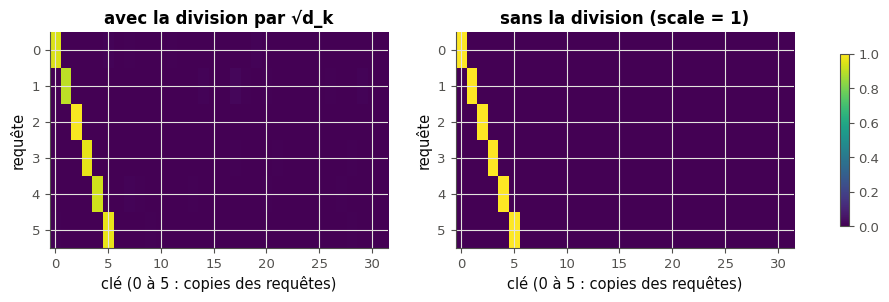

poids de la clé copiée, requête par requête : {'avec la division par √d_k': [0.944, 0.9, 0.989, 0.963, 0.926, 0.968], 'sans la division (scale = 1)': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]}


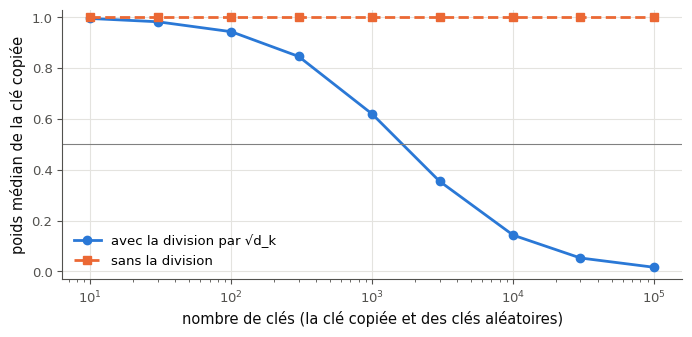

     10 clés : 0,995 avec la division, 1,000000 sans
     30 clés : 0,982 avec la division, 1,000000 sans
    100 clés : 0,943 avec la division, 1,000000 sans
    300 clés : 0,846 avec la division, 1,000000 sans
  1 000 clés : 0,619 avec la division, 1,000000 sans
  3 000 clés : 0,355 avec la division, 1,000000 sans
 10 000 clés : 0,143 avec la division, 1,000000 sans
 30 000 clés : 0,053 avec la division, 1,000000 sans
100 000 clés : 0,017 avec la division, 1,000000 sans
✅ Ex B3.13a : Bravo !
✅ Ex B3.13b : Exact !


In [29]:
if any(answer is ... or answer is None for answer in [exponent_13, keeps_half_13]):
    print("⏳ Ex B3.13 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    # 1. the attention map: 6 queries; keys 0 to 5 copy them, keys 6 to 31 are random (your scaled_dot_product_attention)
    rng_13 = np.random.default_rng(130)
    q_13 = rng_13.normal(size=(6, D_13))
    k_13 = np.vstack([q_13, rng_13.normal(size=(26, D_13))])
    maps_13 = None
    with checked("B3.13"):
        maps_13 = {"avec la division par √d_k": np.asarray(mylearn.attention.scaled_dot_product_attention(q_13, k_13, k_13)[1]),
                   "sans la division (scale = 1)": np.asarray(mylearn.attention.scaled_dot_product_attention(q_13, k_13, k_13, scale=1.0)[1])}
    if maps_13 is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
        for ax, (title, w) in zip(axes, maps_13.items()):
            im = ax.imshow(w, cmap="viridis", vmin=0, vmax=1, aspect="auto")
            ax.set_title(title)
            ax.set_xlabel("clé (0 à 5 : copies des requêtes)")
            ax.set_ylabel("requête")
        fig.colorbar(im, ax=axes, shrink=0.8)
        plt.show()
        print("poids de la clé copiée, requête par requête :",
              {title: np.round(np.diag(w[:, :6]), 3).tolist() for title, w in maps_13.items()})
    else:
        print("⏳ Ex B3.13 : la carte attend ta scaled_dot_product_attention (B3.12) ; la courbe ci-dessous n'en a pas besoin.")

    # 2. the median weight of the copied key over 200 queries, from 10 to 100 000 keys
    medians_13 = {scaled: [float(np.median(copied_weight_13(n, scaled))) for n in KEYS_13] for scaled in (True, False)}
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.semilogx(KEYS_13, medians_13[True], "o-", label="avec la division par √d_k")
    ax.semilogx(KEYS_13, medians_13[False], "s--", label="sans la division")
    ax.axhline(0.5, color="gray", lw=0.8)
    ax.set_xlabel("nombre de clés (la clé copiée et des clés aléatoires)")
    ax.set_ylabel("poids médian de la clé copiée")
    ax.set_ylim(-0.03, 1.03)
    ax.legend()
    plt.show()
    for n_13, with_13, without_13 in zip(KEYS_13, medians_13[True], medians_13[False]):
        print(f"{n_13:>7_} clés : {fr(with_13, 3)} avec la division, {fr(without_13, 6)} sans".replace("_", " "))
    wb.check("B3.13a", exponent_13)
    wb.check("B3.13b", keeps_half_13)

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Relie la courbe « avec la division » à ∂ B3.6 : quel est le score typique de la clé copiée, celui des autres clés, et que compare la softmax ? Refais la courbe avec `d_k = 16`, puis `d_k = 256` (`copied_weight_13(n, True, d_k=…)`) : où se place la bascule, et que corrige exactement la division par $\sqrt{d_k}$ ?

### Ex B3.14 — split_heads, merge_heads et multi_head_attention 🔨 ★★★ ⏱️ 45 min
**Objectif :** découper en têtes, recoller, puis assembler une attention multi-têtes complète, validée contre `nn.MultiheadAttention`.  
**Prérequis :** Ex B3.12 · ✏️ B3.3 · fiche §203.4 (« Une seule matrice pour toutes les têtes », piège du reshape direct) · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `split_heads(x, n_heads)` : `(N, T, D)` → `(N, H, T, D // H)` ; la tête $h$ reçoit les features $h\,d_h$ à $(h + 1)\,d_h - 1$ de chaque token ($d_h = D / H$). `ValueError` si `x` n'est pas 3-D ou si $H$ ne divise pas $D$.
- `merge_heads(x)` : l'inverse, `(N, H, T, d_h)` → `(N, T, H d_h)`, la tête 0 d'abord ; `merge_heads(split_heads(x, H))` redonne `x`. `ValueError` si `x` n'est pas 4-D.
- `multi_head_attention(query, key, value, params, n_heads, mask=None)` rend le couple `(output, weights)`, de formes `(N, L, D)` et `(N, H, L, S)` :
  - $\mathbf{Q} = \text{query}\,\mathbf{W}_q + \mathbf{b}_q$ (de même $\mathbf{K}$ avec `key` et $\mathbf{V}$ avec `value`), le découpage en têtes, ta `scaled_dot_product_attention` (B3.12) dans chaque tête avec son échelle par défaut, le recollage, puis la projection de sortie $\mathbf{W}_o$, $\mathbf{b}_o$ ; l'auto-attention est `query = key = value = x` ;
  - `params` : `W_q`, `W_k`, `W_v`, `W_o` de forme `(D, D)` et `b_q`, `b_k`, `b_v`, `b_o` de forme `(D,)`, dans un mapping quelconque (aussi en lecture seule, `MappingProxyType`) ; ses autres clés sont ignorées (les paramètres d'un bloc entier passent) ; un paramètre manquant lève `ValueError`, pas `KeyError` ;
  - `mask` (`True` = autorisé) de forme `(L, S)`, `(N, 1, 1, S)`, `(N, 1, L, S)` ou `(N, H, L, S)` ; les tests prennent aussi de l'attention croisée, où $L \ne S$.

La première cellule de vérification essaie tes deux fonctions de têtes sur l'exemple de la docstring, contre `view(N, T, H, d_h).transpose(1, 2)` de PyTorch, puis l'aller-retour et deux refus. Elle compare ensuite ton attention multi-têtes à `nn.MultiheadAttention` aux mêmes poids (la fonction `params_from_mha` de la cellule des outils montre la conversion : PyTorch range $\mathbf{W}_q^\top$, $\mathbf{W}_k^\top$, $\mathbf{W}_v^\top$ empilées dans `in_proj_weight`, et attend le masque inversé, `~mask`), en auto-attention causale puis en attention croisée avec un masque de padding, et essaie un paramètre manquant. La seconde lance les 48 tests de l'exercice (`-k "test_split_heads_ or test_merge_heads_ or test_multi_head_attention_"`).

Dans tes notes : un reshape direct `(N, T, D)` → `(N, H, T, d_h)`, sans échange d'axes, donne la bonne forme : quelles features reçoit alors chaque tête (fiche §203.4) ? Pourquoi `params_from_mha` transpose-t-elle chaque bloc de `in_proj_weight` ? Que changerait une échelle $1/\sqrt{D}$ au lieu de $1/\sqrt{d_h}$ ?

In [30]:
with checked("B3.14"):
    A = mylearn.attention
    x_14 = np.arange(12.0).reshape(1, 2, 6)
    h_14 = A.split_heads(x_14, 3)
    if returned("B3.14", "split_heads", h_14):
        verdict("B3.14", np.shape(h_14) == (1, 3, 2, 2) and np.array_equal(np.asarray(h_14)[0, 1], [[2.0, 3.0], [8.0, 9.0]]),
                "split_heads(arange(12).reshape(1, 2, 6), 3) : forme (1, 3, 2, 2), la tête 1 a les features 2 et 3.",
                f"split_heads(x, 3) doit rendre la forme (1, 3, 2, 2) et la tête 1 [[2, 3], [8, 9]] ; reçu la forme "
                f"{np.shape(h_14)} et la tête 1 {np.asarray(h_14)[0, 1].tolist() if np.ndim(h_14) == 4 else '?'}.")
    rng_14 = np.random.default_rng(14)
    x_14 = rng_14.normal(size=(2, 5, 12))
    want_14 = torch.from_numpy(x_14).view(2, 5, 4, 3).transpose(1, 2).numpy()
    same("B3.14", "split_heads(x (2, 5, 12), 4) contre view(2, 5, 4, 3).transpose(1, 2)", A.split_heads(x_14, 4), want_14,
         rtol=0, atol=0)
    same("B3.14", "merge_heads(split_heads(x, 4)), qui doit redonner x", A.merge_heads(A.split_heads(x_14, 4)), x_14, rtol=0, atol=0)
    refuses("B3.14", "split_heads d'un x 2-D", lambda: A.split_heads(np.ones((5, 12)), 4))
    refuses("B3.14", "split_heads avec 5 têtes pour D = 12", lambda: A.split_heads(x_14, 5))

    # multi_head_attention against nn.MultiheadAttention with the same weights (float64)
    torch.manual_seed(14)
    D_14, H_14 = 12, 3
    mha_14 = nn.MultiheadAttention(D_14, H_14, batch_first=True).double()
    params_14 = params_from_mha(mha_14) | {"ln1_gamma": np.ones(D_14)}         # an extra key: ignored
    saved_14 = {name: p.copy() for name, p in params_14.items()}
    xt_14 = torch.from_numpy(x_14)
    with torch.no_grad():
        want_o, want_w = mha_14(xt_14, xt_14, xt_14, attn_mask=torch.from_numpy(~causal_np(5)), average_attn_weights=False)
    out_14, w_14 = pair("B3.14", "multi_head_attention", A.multi_head_attention(x_14, x_14, x_14, MappingProxyType(params_14), H_14,
                                                                             mask=causal_np(5)), names=("output", "weights"))
    same("B3.14", "auto-attention causale (2, 5, 12), 3 têtes, contre nn.MultiheadAttention (masque ~mask)", out_14, want_o.numpy(),
         rtol=1e-6, atol=1e-6)
    same("B3.14", "poids par tête (2, 3, 5, 5)", w_14, want_w.numpy(), rtol=1e-6, atol=1e-6)
    enc_14 = rng_14.normal(size=(2, 9, D_14))
    keys_14 = np.arange(9) < np.array([9, 6])[:, None]                        # sequence 1: 6 real keys out of 9
    with torch.no_grad():
        want_x, _ = mha_14(xt_14, torch.from_numpy(enc_14), torch.from_numpy(enc_14), key_padding_mask=torch.from_numpy(~keys_14))
    out_x, w_x = pair("B3.14", "multi_head_attention", A.multi_head_attention(x_14, enc_14, enc_14, params_14, H_14,
                                                                           mask=keys_14[:, None, None, :]), names=("output", "weights"))
    same("B3.14", "attention croisée (5 requêtes, 9 clés) avec un masque de padding (2, 1, 1, 9)", out_x, want_x.numpy(),
         rtol=1e-6, atol=1e-6)
    verdict("B3.14", all(np.array_equal(params_14[name], saved_14[name]) for name in saved_14),
            "les paramètres reçus n'ont pas changé.", "multi_head_attention a modifié les paramètres reçus.")
    no_wo_14 = {name: p for name, p in params_14.items() if name != "W_o"}
    refuses("B3.14", "multi_head_attention sans W_o (ValueError, pas KeyError)",
            lambda: A.multi_head_attention(x_14, x_14, x_14, no_wo_14, H_14))

✅ Ex B3.14 : split_heads(arange(12).reshape(1, 2, 6), 3) : forme (1, 3, 2, 2), la tête 1 a les features 2 et 3.
✅ Ex B3.14 : split_heads(x (2, 5, 12), 4) contre view(2, 5, 4, 3).transpose(1, 2) : un tableau (2, 4, 5, 3), comme attendu.
✅ Ex B3.14 : merge_heads(split_heads(x, 4)), qui doit redonner x : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : split_heads d'un x 2-D : ValueError levée (x must be 3-D of shape (N, T, D), got shape (5, 12)).
✅ Ex B3.14 : split_heads avec 5 têtes pour D = 12 : ValueError levée (n_heads = 5 must divide D = 12).
✅ Ex B3.14 : auto-attention causale (2, 5, 12), 3 têtes, contre nn.MultiheadAttention (masque ~mask) : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : poids par tête (2, 3, 5, 5) : un tableau (2, 3, 5, 5), comme attendu.
✅ Ex B3.14 : attention croisée (5 requêtes, 9 clés) avec un masque de padding (2, 1, 1, 9) : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : les paramètres reçus n'ont pas changé.
✅ Ex B3.14 : multi_head_attention sans 

In [31]:
if written(lambda: mylearn.attention.split_heads(np.ones((1, 2, 4)), 2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_split_heads_ or test_merge_heads_ or test_multi_head_attention_")   # 48 tests
else:
    print("⏳ Ex B3.14 : les tests attendent tes fonctions.")

pytest: 48 passed, 120 deselected in 1.49s


### Ex B3.15 — positional_encoding et apply_rope 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire l'encodage sinusoïdal et RoPE, et vérifier leurs propriétés et la convention de Hugging Face.  
**Prérequis :** ✏️ B3.4 · ∂ B3.7 · fiche §203.5 (« L'encodage sinusoïdal (2017) », « RoPE : tourner les requêtes et les clés ») · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `positional_encoding(seq_len, d_model, base=10000.0)` : le tableau `(T, D)` en float64 de $PE_{p, 2i} = \sin(p / \text{base}^{2i/D})$ et $PE_{p, 2i+1} = \cos(p / \text{base}^{2i/D})$, pour $i = 0 \dots D/2 - 1$. `base = 1` est accepté ; `ValueError` si `d_model` est impair, ou si `seq_len`, `d_model` ou `base` est < 1. Les tests vont jusqu'à $T = 1\,000$ : B5 s'en resservira.
- `apply_rope(x, positions=None, base=10000.0)` : `x` de forme `(..., T, d)`, $d$ pair, une requête ou une clé par position ; la convention **« rotate half »** de Hugging Face (Llama) : la dimension $i$ est appariée avec $i + d/2$ (pour $i < d/2$), pas avec $i + 1$ comme dans l'article de RoFormer, et la paire $(x_1, x_2)$ tourne de l'angle $\theta = \text{position} \cdot \text{base}^{-2i/d}$ :
  $(x_1 \cos\theta - x_2 \sin\theta,\ x_2 \cos\theta + x_1 \sin\theta)$ ;
  - `positions` : exactement $T$ positions (`np.arange(T)` si `None`) ; une seule position pour $T$ vecteurs est refusée, même si NumPy la diffuserait ;
  - rend un tableau de la forme de `x` ; `ValueError` si $d$ est impair ou si `positions` n'a pas la longueur $T$ ;
  - comparé à `LlamaRotaryEmbedding` et `apply_rotary_pos_emb` de transformers, à $10^{-5}$ (ils calculent les angles en float32).

La première cellule de vérification essaie ton encodage sur l'exemple de la docstring, sur 1 000 positions et sur la propriété du décalage (§203.5 : décaler de 7 positions applique la même rotation à chaque paire (sin, cos)), puis RoPE sur l'exemple de la docstring, la conservation des normes, la propriété relative (le produit scalaire ne dépend que de $m - n$, ∂ B3.7) et contre `LlamaRotaryEmbedding` ; enfin quatre refus. La seconde lance les 40 tests de l'exercice (`-k "test_positional_encoding_ or test_apply_rope_"`).

Dans tes notes : pourquoi RoPE tourne-t-il les requêtes et les clés, mais pas les valeurs ? Le produit scalaire d'une requête et d'une clé change-t-il quand on décale toutes les positions de 1 000 (`positions = np.arange(T) + 1000`) ? Mesure-le. Qu'apporte la convention « rotate half » par rapport aux paires $(2i, 2i + 1)$, et que perd-on à confondre les deux ?

In [32]:
with checked("B3.15"):
    A = mylearn.attention
    pos_15 = np.arange(3)[:, None] / 10000.0 ** (np.arange(0, 4, 2) / 4)       # the formula of the docstring
    want_15 = np.stack([np.sin(pos_15), np.cos(pos_15)], axis=-1).reshape(3, 4)
    same("B3.15", "positional_encoding(3, 4)", A.positional_encoding(3, 4), want_15, rtol=1e-6, atol=1e-6)
    pe_15 = np.asarray(A.positional_encoding(1000, 64))
    verdict("B3.15", pe_15.shape == (1000, 64) and pe_15.dtype == np.float64 and np.abs(pe_15).max() <= 1,
            "positional_encoding(1000, 64) : forme (1000, 64), float64, valeurs dans [−1, 1].",
            f"positional_encoding(1000, 64) : attendu un tableau float64 (1000, 64) dans [−1, 1] ; reçu {pe_15.dtype} {pe_15.shape}.")
    omega_15 = 10000.0 ** (-np.arange(32) / 32)                                  # one frequency per (sin, cos) pair
    c_15, s_15 = np.cos(7 * omega_15), np.sin(7 * omega_15)
    sin_15, cos_15 = pe_15[:-7, 0::2], pe_15[:-7, 1::2]
    shifted_15 = np.stack([sin_15 * c_15 + cos_15 * s_15, cos_15 * c_15 - sin_15 * s_15], axis=-1).reshape(993, 64)
    same("B3.15", "un décalage de 7 positions = une rotation fixe de chaque paire (sin, cos) (§203.5)", pe_15[7:], shifted_15,
         rtol=1e-6, atol=1e-6)
    refuses("B3.15", "positional_encoding(4, 5) (d_model impair)", lambda: A.positional_encoding(4, 5))
    refuses("B3.15", "positional_encoding(0, 4)", lambda: A.positional_encoding(0, 4))

    ones_15 = np.ones((3, 4))
    half_15 = 10000.0 ** (-2 * np.arange(2) / 4)                                  # theta = position * base**(-2i/d)
    z_15 = (1 + 1j) * np.exp(1j * np.arange(3)[:, None] * half_15)                # pair (x_i, x_{i+d/2}) as x_i + i x_{i+d/2}
    same("B3.15", "apply_rope(np.ones((3, 4))) (paires (i, i + d/2))", A.apply_rope(ones_15),
         np.concatenate([z_15.real, z_15.imag], axis=1), rtol=1e-6, atol=1e-6)
    rng_15 = np.random.default_rng(15)
    x_15 = rng_15.normal(size=(2, 3, 10, 8))
    same("B3.15", "normes de apply_rope(x (2, 3, 10, 8)), égales à celles de x", np.linalg.norm(A.apply_rope(x_15), axis=-1),
         np.linalg.norm(x_15, axis=-1), rtol=1e-6, atol=1e-6)
    q_15, k_15 = rng_15.normal(size=(1, 8)), rng_15.normal(size=(1, 8))
    dots_15 = [(np.asarray(A.apply_rope(q_15, [m])) @ np.asarray(A.apply_rope(k_15, [n])).T).item()
               for m, n in ((3, 1), (12, 10), (102, 100))]
    verdict("B3.15", np.allclose(dots_15, dots_15[0], rtol=1e-6, atol=1e-6),
            "⟨RoPE(q, m), RoPE(k, n)⟩ ne dépend que de m − n : " + ", ".join(fr(d, 4) for d in dots_15) + " pour (3, 1), (12, 10), (102, 100).",
            "⟨RoPE(q, m), RoPE(k, n)⟩ doit être le même pour (3, 1), (12, 10) et (102, 100) (m − n = 2) ; reçu "
            + ", ".join(fr(d, 4) for d in dots_15) + ".")
    try:
        from transformers.models.llama.configuration_llama import LlamaConfig
        from transformers.models.llama.modeling_llama import LlamaRotaryEmbedding, apply_rotary_pos_emb
    except ImportError:
        print("⏳ Ex B3.15 : la comparaison à LlamaRotaryEmbedding attend la bibliothèque transformers (Colab).")
    else:
        config_15 = LlamaConfig(hidden_size=24, num_attention_heads=3, head_dim=8, max_position_embeddings=128,
                                rope_parameters={"rope_type": "default", "rope_theta": 10000.0})
        cos_hf, sin_hf = LlamaRotaryEmbedding(config_15)(torch.from_numpy(x_15), torch.arange(10)[None, :])
        want_hf, _ = apply_rotary_pos_emb(torch.from_numpy(x_15), torch.from_numpy(x_15), cos_hf, sin_hf)
        same("B3.15", "apply_rope(x) contre LlamaRotaryEmbedding + apply_rotary_pos_emb de transformers (angles en float32 : 1e-5)",
             A.apply_rope(x_15), want_hf.numpy(), rtol=1e-5, atol=1e-5)
    refuses("B3.15", "apply_rope(np.ones((3, 4)), positions=[0]) (une position pour trois vecteurs)",
            lambda: A.apply_rope(ones_15, positions=[0]))
    refuses("B3.15", "apply_rope(np.ones((3, 5))) (d impair)", lambda: A.apply_rope(np.ones((3, 5))))

✅ Ex B3.15 : positional_encoding(3, 4) : un tableau (3, 4), comme attendu.
✅ Ex B3.15 : positional_encoding(1000, 64) : forme (1000, 64), float64, valeurs dans [−1, 1].
✅ Ex B3.15 : un décalage de 7 positions = une rotation fixe de chaque paire (sin, cos) (§203.5) : un tableau (993, 64), comme attendu.
✅ Ex B3.15 : positional_encoding(4, 5) (d_model impair) : ValueError levée (d_model must be even, got 5).
✅ Ex B3.15 : positional_encoding(0, 4) : ValueError levée (seq_len must be >= 1, got 0).
✅ Ex B3.15 : apply_rope(np.ones((3, 4))) (paires (i, i + d/2)) : un tableau (3, 4), comme attendu.
✅ Ex B3.15 : normes de apply_rope(x (2, 3, 10, 8)), égales à celles de x : un tableau (2, 3, 10), comme attendu.
✅ Ex B3.15 : ⟨RoPE(q, m), RoPE(k, n)⟩ ne dépend que de m − n : 1,6224, 1,6224, 1,6224 pour (3, 1), (12, 10), (102, 100).
✅ Ex B3.15 : apply_rope(x) contre LlamaRotaryEmbedding + apply_rotary_pos_emb de transformers (angles en float32 : 1e-5) : un tableau (2, 3, 10, 8), comme attendu.
✅ Ex

In [33]:
if written(lambda: mylearn.attention.positional_encoding(2, 2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_positional_encoding_ or test_apply_rope_")   # 40 tests
else:
    print("⏳ Ex B3.15 : les tests attendent tes fonctions.")

pytest: 40 passed, 128 deselected in 4.71s


### Ex B3.16 — transformer_block en NumPy, validé contre nn.TransformerEncoderLayer 🔨 ★★★★ ⏱️ 100 min
**Objectif :** assembler un bloc Transformer pré-LN complet en NumPy, et le valider au millionième contre PyTorch.  
**Prérequis :** Ex B3.14 · ch. 20 (layer norm, 20.17) · ch. 17 (GELU, 17.14) · fiche §203.6 (« Pré-LN ou post-LN », « Le bloc en équations, et sa vérification ») · **mylearn :** `attention.py` · **Parcours :** C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat** de `transformer_block(x, params, n_heads, mask=None, eps=1e-5)`, le bloc pré-LN de GPT-2, sans dropout :
- $\mathbf{h} = \mathbf{x} + \operatorname{MHA}(\operatorname{LN}_1(\mathbf{x}))$ en auto-attention (ta `multi_head_attention`, avec `mask`), puis $\text{out} = \mathbf{h} + \operatorname{gelu}(\operatorname{LN}_2(\mathbf{h})\,\mathbf{W}_1 + \mathbf{b}_1)\,\mathbf{W}_2 + \mathbf{b}_2$ ;
- la GELU **exacte** (avec la fonction d'erreur), pas l'approximation tanh ; `eps` sert aux **deux** layer norms ;
- `params` : les clés de `multi_head_attention`, plus `ln1_gamma`, `ln1_beta`, `ln2_gamma`, `ln2_beta` de forme `(D,)`, `W_1` `(D, F)`, `b_1` `(F,)`, `W_2` `(F, D)` et `b_2` `(D,)` ; la largeur $F$ du MLP se lit dans `W_1` ; un paramètre manquant lève `ValueError` ;
- rend `(N, T, D)` ; `x` et `params` ne sont pas modifiés.

**Tes fonctions des ch. 17 et 20.** Le stub importe ta `gelu` (`nn/activations.py`, Ex 17.14) et ta `layer_norm` (`nn/regularization.py`, Ex 20.17) : réutilise-les. Si l'un de ces fichiers manque dans ta librairie, la référence le remplace (une ligne ℹ️ le dit). S'il existe mais que la fonction n'est pas encore écrite, la première cellule de vérification te le signale : écris-la (son exercice), ou recode la layer norm et la GELU dans `attention.py`, ce que les tests acceptent aussi. Les tests passent par tes fonctions si tu les réutilises : si l'un d'eux échoue, lance d'abord les tests de 17.14 et de 20.17 (le message de l'échec le dit).

La première cellule de vérification construit le même bloc en PyTorch, `nn.TransformerEncoderLayer(16, 4, 64, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)` en float64, recopie ses poids dans ta convention (`block_params_from_torch` dans la cellule des outils : `W = weight.T` pour chaque couche dense), et compare ta sortie à la sienne avec le masque causal (passé à PyTorch en `~mask`), sans masque, puis avec `eps = 0.1` ; elle essaie enfin un paramètre manquant. La seconde lance les 25 tests de l'exercice (`-k "test_transformer_block_"`).

Dans tes notes : avec tous les poids à zéro (l'exemple de la docstring), que rend ton bloc, et que dit ce résultat des connexions résiduelles ? En quoi ton bloc changerait-il pour un post-LN (§203.6) ? Remplace ta GELU par l'approximation tanh : de combien ta sortie s'écarte-t-elle de celle de PyTorch, et le test l'aurait-il vu ?

In [34]:
with checked("B3.16"):
    A = mylearn.attention
    for name_16, probe_16, where_16 in (
            ("gelu", lambda: mylearn.nn.activations.gelu(np.zeros(2)), "nn/activations.py, Ex 17.14"),
            ("layer_norm", lambda: mylearn.nn.regularization.layer_norm(np.zeros((1, 4)), np.ones(4), np.zeros(4)),
             "nn/regularization.py, Ex 20.17")):
        if not written(probe_16):
            print(f"ℹ️ Ex B3.16 : ta {name_16} ({where_16}) n'est pas encore écrite : écris-la, ou recode-la dans "
                  "transformer_block (l'énoncé le permet).")
    # the same block in PyTorch: nn.TransformerEncoderLayer, pre-LN, exact GELU, no dropout, in float64
    torch.manual_seed(16)
    D_16, H_16, F_16 = 16, 4, 64
    layer_16 = nn.TransformerEncoderLayer(D_16, H_16, F_16, dropout=0.0, activation="gelu", batch_first=True,
                                          norm_first=True).double().eval()
    params_16 = block_params_from_torch(layer_16)
    saved_16 = {name: p.copy() for name, p in params_16.items()}
    x_16 = np.random.default_rng(16).normal(size=(2, 7, D_16))
    x_copy_16 = x_16.copy()
    with torch.no_grad():
        want_c16 = layer_16(torch.from_numpy(x_16), src_mask=torch.from_numpy(~causal_np(7))).numpy()
        want_n16 = layer_16(torch.from_numpy(x_16)).numpy()
    same("B3.16", "transformer_block(x (2, 7, 16), 4 têtes, masque causal) contre nn.TransformerEncoderLayer(norm_first=True)",
         A.transformer_block(x_16, params_16, H_16, mask=causal_np(7)), want_c16, rtol=1e-6, atol=1e-6)
    same("B3.16", "le même bloc sans masque (un encodeur)", A.transformer_block(x_16, params_16, H_16), want_n16,
         rtol=1e-6, atol=1e-6)
    layer_e16 = nn.TransformerEncoderLayer(D_16, H_16, F_16, dropout=0.0, activation="gelu", batch_first=True,
                                           norm_first=True, layer_norm_eps=0.1).double().eval()
    layer_e16.load_state_dict(layer_16.state_dict())
    with torch.no_grad():
        want_e16 = layer_e16(torch.from_numpy(x_16)).numpy()
    same("B3.16", "eps=0.1 (les deux layer norms)", A.transformer_block(x_16, params_16, H_16, eps=0.1), want_e16,
         rtol=1e-6, atol=1e-6)
    verdict("B3.16", np.array_equal(x_16, x_copy_16) and all(np.array_equal(params_16[k], saved_16[k]) for k in saved_16),
            "x et les paramètres reçus n'ont pas changé.", "transformer_block a modifié x ou les paramètres reçus.")
    no_w1_16 = {name: p for name, p in params_16.items() if name != "W_1"}
    refuses("B3.16", "transformer_block sans W_1 (ValueError, pas KeyError)", lambda: A.transformer_block(x_16, no_w1_16, H_16))

✅ Ex B3.16 : transformer_block(x (2, 7, 16), 4 têtes, masque causal) contre nn.TransformerEncoderLayer(norm_first=True) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : le même bloc sans masque (un encodeur) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : eps=0.1 (les deux layer norms) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : x et les paramètres reçus n'ont pas changé.
✅ Ex B3.16 : transformer_block sans W_1 (ValueError, pas KeyError) : ValueError levée (missing parameter(s): W_1).


In [35]:
if written(lambda: mylearn.attention.transformer_block(np.zeros((1, 1, 2)), {}, 1)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_transformer_block_")   # 25 tests
else:
    print("⏳ Ex B3.16 : les tests attendent ta fonction transformer_block.")

pytest: 25 passed, 143 deselected in 1.81s


### Ex B3.17 — Trois masques qui mentent : convention inversée, masque transposé, padding compté dans la loss 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les trois erreurs de masque d'un petit modèle de langue, guidé par des diagnostics enchaînés.  
**Prérequis :** Ex B3.12 · fiche §203.3 (encadrés 🕰️ sur `F.scaled_dot_product_attention` et `nn.MultiheadAttention`), §203.8 (« La loss et la perplexité ») · tableau des pièges ⚠️ · **Fil rouge :** Holmes · **Parcours :** R, C

Une collègue a écrit un petit modèle de langue au niveau caractère : une couche d'attention causale sur les embeddings des caractères et de leurs positions, puis une couche dense. Elle calculait d'abord l'attention avec `F.scaled_dot_product_attention`, puis elle est passée à `nn.MultiheadAttention` pour lire les poids d'attention. Le modèle s'entraîne sur des lignes de Holmes de longueurs différentes, complétées par du padding. Son code contient **trois** erreurs. Corrige-le **sur place**, dans sa cellule, sans changer les noms, les signatures ni ce que rendent les fonctions.

Ce qu'il devrait faire :
- `causal_mask_17(T)` : le masque causal `(T, T)` dans la convention de `F.scaled_dot_product_attention`, `True` là où la requête $i$ peut regarder la clé $j$ ;
- `TinyLM_17` : des ids `(N, T)` → des logits `(N, T, V)`, chaque position ne voyant que les caractères jusqu'à elle ; `self.weights` garde les poids d'attention (la moyenne des deux têtes) ;
- `lm_loss_17(logits, targets)` : la cross-entropy moyenne sur les **vrais** caractères du batch ; les cibles valent `PAD_17` sur le padding.

La cellule donnée prépare les données : `LINES_17` (des lignes de l'entraînement de Holmes, de 24 à 64 caractères), `batch_17` (un batch de lignes, entrées et cibles décalées d'un caractère, complétées par `PAD_17`), `VAL_17` (64 fenêtres de 64 caractères de la validation, sans padding). Elle définit aussi `diagnose_17`. La cellule de vérification lance `diagnose_17`, trois diagnostics enchaînés, chacun ne s'exécutant que si le précédent passe, car une erreur peut en cacher une autre :
- la loss d'un batch est-elle un nombre ?
- le modèle voit-il le futur ? (un caractère changé, puis 200 itérations d'entraînement, quelques secondes)
- la loss d'un batch dépend-elle de son padding ?

Elle tourne dès le premier « Tout exécuter » : ses messages sont ton point de départ. Une fois les trois points passés, la cellule suivante trace les poids d'attention de ta version réparée sur une ligne de Holmes.

Dans tes notes : les trois erreurs, et pour chacune le symptôme qu'elle produirait seule. Pourquoi les `nan` n'apparaissent-ils qu'à une seule position, et laquelle, selon que l'autre erreur de masque est encore là ou non ? Laquelle des trois erreurs fait baisser la loss d'entraînement sans que le modèle prédise mieux le texte ?

In [36]:
PAD_17 = len(DATA.itos)                    # one more id for the padding: 89 ids in all
VOCAB_17, LEN_17 = PAD_17 + 1, 64
LINES_17 = [line for line in DATA.train_text.split("\n") if 24 <= len(line) <= LEN_17]    # lines of Holmes
VAL_17 = DATA.val_ids[:LEN_17 * 64].view(64, LEN_17)                                       # 64 windows, no padding


def batch_17(lines, generator, batch_size=32):
    """A batch of lines of Holmes: inputs ids[:-1] and targets ids[1:], padded with PAD_17 to LEN_17 - 1 positions."""
    picks = torch.randint(len(lines), (batch_size,), generator=generator).tolist()
    width = max(len(lines[i]) for i in picks) - 1
    x = torch.full((batch_size, width), PAD_17)
    y = torch.full((batch_size, width), PAD_17)
    for row, i in enumerate(picks):
        ids = DATA.encode(lines[i])
        x[row, :len(ids) - 1], y[row, :len(ids) - 1] = ids[:-1], ids[1:]
    return x, y


def diagnose_17(model_class, loss_fn, iters=200):
    """Three diagnoses of the small language model, in a row: the first one that fails stops the chain (one error can
    hide another). Returns the trained model when the three pass, else None."""
    torch.manual_seed(17)
    model = model_class(VOCAB_17)
    gen = torch.Generator().manual_seed(17)
    x, y = batch_17(LINES_17, gen)

    def point1():
        with torch.no_grad():
            logits = model(x)
            loss = loss_fn(logits, y)
        if torch.isfinite(loss) and torch.isfinite(logits).all():
            return True, f"la loss d'un batch à l'initialisation est un nombre, {fr(loss.item(), 3)}", ""
        bad = sorted({int(t) for t in torch.nonzero(~torch.isfinite(logits).all(dim=-1))[:, 1]})
        return False, (f"la loss d'un batch vaut {loss.item()} ; les logits sont nan à la position {bad[0]} de chaque séquence"
                       if len(bad) == 1 else f"la loss d'un batch vaut {loss.item()} ; logits nan aux positions {bad[:6]}"), \
            "que voit cette position dans la couche d'attention ?"

    def point2():
        probe = VAL_17[:4].clone()
        changed = probe.clone()
        changed[:, 40] = (changed[:, 40] + 1) % PAD_17                      # change the character 40 of each window
        with torch.no_grad():
            gap = (model(probe)[:, :40] - model(changed)[:, :40]).abs().max().item()
        optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
        for _ in range(iters):
            xb, yb = batch_17(LINES_17, gen)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            val = F.cross_entropy(model(VAL_17[:, :-1]).flatten(0, 1), VAL_17[:, 1:].flatten()).item()
        if gap < 1e-6:
            return True, (f"changer le caractère 40 d'une fenêtre ne change aucun logit des positions 0 à 39 ; après "
                          f"{iters} itérations, la loss de validation vaut {fr(val, 2)} nats par caractère"), ""
        return False, (f"changer le caractère 40 d'une fenêtre change les logits des positions 0 à 39 (écart maximal "
                       f"{gap:.2g}) ; après {iters} itérations, la loss de validation tombe à {fr(val, 2)} nat par "
                       "caractère"), "pour un modèle d'une seule couche, est-ce crédible ? D'où vient l'information ?"

    def point3():
        short = [line for line in LINES_17 if len(line) <= 40][:16]
        width = max(len(line) for line in short) - 1
        x_s = torch.full((16, width), PAD_17)
        y_s = torch.full((16, width), PAD_17)
        for row, line in enumerate(short):
            ids = DATA.encode(line)
            x_s[row, :len(ids) - 1], y_s[row, :len(ids) - 1] = ids[:-1], ids[1:]
        extra = 60 - width                                                   # the same lines, 60 positions wide
        x_l = torch.cat([x_s, torch.full((16, extra), PAD_17)], dim=1)
        y_l = torch.cat([y_s, torch.full((16, extra), PAD_17)], dim=1)
        with torch.no_grad():
            short_loss, long_loss = loss_fn(model(x_s), y_s).item(), loss_fn(model(x_l), y_l).item()
        if abs(short_loss - long_loss) < 1e-5:
            return True, (f"la loss d'un même batch ne dépend pas de son padding ({fr(short_loss, 4)} sur {width} "
                          f"positions comme sur 60)"), ""
        return False, (f"la loss d'un même batch de 16 lignes vaut {fr(short_loss, 4)} sur {width} positions et "
                       f"{fr(long_loss, 4)} une fois complété par {extra} positions de padding"), \
            "quelles positions entrent dans la moyenne ?"

    points = [("la loss est un nombre", point1), ("le modèle ne voit pas le futur", point2),
              ("le padding ne compte pas", point3)]
    for k, (name, run) in enumerate(points, start=1):
        ok, measured, why = run()
        if ok:
            print(f"✅ Ex B3.17 : point {k}, {name} ({measured}).")
        else:
            print(f"❌ Ex B3.17 : point {k} : {measured} ; {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex B3.17 : point {later} : corrige d'abord le point {k}.")
            return None
    print("✅ Ex B3.17 : les trois diagnostics passent.")
    return model

In [37]:
def causal_mask_17(T):
    """Boolean causal mask in the convention of F.scaled_dot_product_attention: True where query i may attend to key j."""
    return torch.ones(T, T, dtype=torch.bool).tril()                           # 2. the lower triangle: j <= i


class TinyLM_17(nn.Module):
    """One causal attention layer over character and position embeddings, then a dense layer: ids (N, T) -> logits
    (N, T, vocab_size)."""

    def __init__(self, vocab_size, d_model=32, n_head=2, max_len=64):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        self.attn = nn.MultiheadAttention(d_model, n_head, batch_first=True)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, ids):
        T = ids.shape[1]
        x = self.tok(ids) + self.pos(torch.arange(T))
        h, self.weights = self.attn(x, x, x, attn_mask=~causal_mask_17(T))    # 1. nn.MultiheadAttention: True = masked
        return self.head(self.ln(x + h))


def lm_loss_17(logits, targets):
    """Mean cross-entropy over the real characters of a batch: logits (N, T, V), targets (N, T) with PAD_17 on the
    padding."""
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                           ignore_index=PAD_17)                                # 3. the padding is left out of the mean


with checked("B3.17"):
    model_17 = diagnose_17(TinyLM_17, lm_loss_17)

✅ Ex B3.17 : point 1, la loss est un nombre (la loss d'un batch à l'initialisation est un nombre, 4,581).


✅ Ex B3.17 : point 2, le modèle ne voit pas le futur (changer le caractère 40 d'une fenêtre ne change aucun logit des positions 0 à 39 ; après 200 itérations, la loss de validation vaut 2,76 nats par caractère).
✅ Ex B3.17 : point 3, le padding ne compte pas (la loss d'un même batch ne dépend pas de son padding (2,8388 sur 39 positions comme sur 60)).
✅ Ex B3.17 : les trois diagnostics passent.


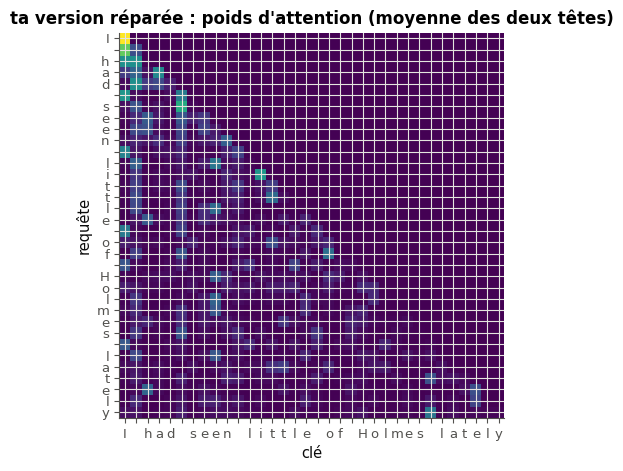

au-dessus de la diagonale, le plus grand poids vaut 0,000000


In [38]:
if globals().get("model_17") is None:
    print("⏳ Ex B3.17 : la carte attend que les trois points de la cellule précédente passent.")
else:
    with checked("B3.17"):
        line_17 = "I had seen little of Holmes lately."                  # a line of the first story
        ids_17 = DATA.encode(line_17)[None, :-1]
        model_17.eval()
        with torch.no_grad():
            logits_17 = model_17(ids_17)
        w_17 = model_17.weights[0].numpy()                                 # (T, T), averaged over the 2 heads
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.imshow(w_17, cmap="viridis")
        ax.set_xticks(range(len(line_17) - 1), list(line_17[:-1]))
        ax.set_yticks(range(len(line_17) - 1), list(line_17[:-1]))
        ax.set_xlabel("clé")
        ax.set_ylabel("requête")
        ax.set_title("ta version réparée : poids d'attention (moyenne des deux têtes)")
        plt.show()
        print("au-dessus de la diagonale, le plus grand poids vaut", fr(float(np.triu(w_17, 1).max()), 6))

## Partie B · Le mini-GPT en PyTorch

Tu passes de NumPy à PyTorch : le module d'attention causale du mini-GPT, comparé à ta version NumPy (B3.18), le modèle complet (B3.19), puis son entraînement sur Holmes, face au LSTM du ch. 22 (B3.20). Le modèle suit la structure de nanoGPT (A. Karpathy, licence MIT, fiche §203.8) ; le contrat interdit `nn.Transformer…` et `nn.MultiheadAttention` dans ton modèle.

Le modèle que B3.20 entraîne est **sauvegardé une fois** (son `state_dict`, sa configuration, le vocabulaire et l'historique de l'entraînement), hors du dépôt, sous une clé qui dit tout ce qui l'a produit (configuration, réglages, graine, mode rapide ou complet, empreinte du découpage) : la suite du chapitre le recharge sans réentraîner. Ton modèle doit donc suivre les noms du contrat de B3.19.

La cellule suivante charge les outils de la partie : `MINI_CONFIG` (4 blocs, 4 têtes, $d = 128$, contexte de 128 caractères, 88 caractères), `n_params`, `forbidden_in` (les modules interdits trouvés dans un modèle), `params_from_qkv` (les poids de ton module d'attention dans la convention de `multi_head_attention`). Le vocabulaire est celui de ton `build_vocab` (ch. 22) : les caractères par fréquence décroissante, à égalité dans l'ordre de `sorted` ; la cellule vérifie que ta fonction donne le même. `wb.gpt` contient aussi une solution de référence de B3.18 à B3.20 (`ReferenceGPT`, `train`) : le notebook ne s'en sert que pour vérifier tes fonctions ou quand ton modèle manque ; ne la lis qu'une fois ta version écrite.

In [39]:
# Tools of part B: the mini-GPT in PyTorch
MINI_CONFIG = dict(wbgpt.MINI_CONFIG)          # 4 blocks, 4 heads, d = 128, context of 128 characters, 88 ids
FORBIDDEN = (nn.MultiheadAttention, nn.Transformer, nn.TransformerEncoder, nn.TransformerDecoder,
             nn.TransformerEncoderLayer, nn.TransformerDecoderLayer)


def n_params(model):
    """The number of parameters of a module, each tied parameter counted once (model.parameters() lists it once)."""
    return sum(p.numel() for p in model.parameters())


def forbidden_in(model):
    """The names of the ready-made attention modules of PyTorch found in a model (the contract forbids them)."""
    return sorted({type(m).__name__ for m in model.modules() if isinstance(m, FORBIDDEN)})


def params_from_qkv(qkv, proj):
    """The parameters of an attention module (qkv: nn.Linear(d, 3d), queries then keys then values; proj:
    nn.Linear(d, d)) in the convention of multi_head_attention (z = x @ W + b, float64): W = weight.T."""
    D = proj.in_features
    W = qkv.weight.detach().double().numpy()
    b = qkv.bias.detach().double().numpy()
    return {"W_q": W[:D].T.copy(), "W_k": W[D:2 * D].T.copy(), "W_v": W[2 * D:].T.copy(),
            "W_o": proj.weight.detach().double().numpy().T.copy(), "b_q": b[:D].copy(), "b_k": b[D:2 * D].copy(),
            "b_v": b[2 * D:].copy(), "b_o": proj.bias.detach().double().numpy().copy()}


try:                                                   # the vocabulary: the rule of your build_vocab (ch. 22, 22.12)
    _, itos_vocab = mylearn.sequences.build_vocab(DATA.train_text + DATA.val_text)
    print("ℹ️ ton build_vocab (ch. 22) donne le vocabulaire de DATA :" if list(itos_vocab) == DATA.itos else
          "⚠️ ton build_vocab (ch. 22) ne donne pas le vocabulaire de DATA (décroissance de la fréquence, ex aequo dans "
          "l'ordre de sorted) : le notebook garde celui de DATA, relance les tests du ch. 22 ;",
          f"{len(DATA.itos)} caractères, les plus fréquents {DATA.itos[:6]}.")
except Exception:                                     # not written yet (NotImplementedError), or no module at all
    print(f"ℹ️ ton build_vocab (ch. 22, 22.12) n'est pas écrit : le notebook prend le vocabulaire de DATA, construit par "
          f"la même règle ({len(DATA.itos)} caractères).")

ℹ️ ton build_vocab (ch. 22) donne le vocabulaire de DATA : 88 caractères, les plus fréquents [' ', 'e', 't', 'a', 'o', 'n'].


### Ex B3.18 — De NumPy à PyTorch : un module CausalSelfAttention avec F.scaled_dot_product_attention 📦 ★★ ⏱️ 30 min
**Objectif :** écrire le module d'attention causale du mini-GPT en PyTorch, et mesurer son écart à ta version NumPy.  
**Prérequis :** Ex B3.14 · ch. 20 (`nn.Module`, dropout) · fiche §203.3 (encadré 🕰️ sur `F.scaled_dot_product_attention`), §203.4 · **Parcours :** R, M, C

**Contrat** de `CausalSelfAttention_18(d_model, n_head, dropout=0.0)`, un `nn.Module` :
- exactement deux couches denses, avec biais : `qkv = nn.Linear(d_model, 3 * d_model)`, dont les sorties sont, dans l'ordre, les requêtes, les clés puis les valeurs ; et `proj = nn.Linear(d_model, d_model)`, la projection de sortie $\mathbf{W}_O$ ; `ValueError` si `n_head` ne divise pas `d_model` ;
- `forward(x)` : `x` de forme `(N, T, d_model)` → `(N, T, d_model)` : le découpage en `n_head` têtes comme ton `split_heads` (B3.14), l'attention causale par `F.scaled_dot_product_attention` avec son échelle par défaut, le recollage des têtes comme `merge_heads`, puis `proj` ;
- dropout : `dropout` sur les poids d'attention (`dropout_p`) et un `nn.Dropout(dropout)` sur la sortie de `proj`, en mode train seulement ; en mode eval, aucun dropout (`dropout_p = 0`, fiche §203.3) ;
- ni `nn.MultiheadAttention` ni `nn.Transformer…`.

La cellule de vérification contrôle les noms et les formes des paramètres, puis compare ta sortie, en mode eval, à celle de `nn.MultiheadAttention` aux mêmes poids, avec le masque causal (l'oracle de PyTorch), et à ta `multi_head_attention` NumPy de B3.14 avec les mêmes poids, convertis par `params_from_qkv` (`W = weight.T`). L'écart maximal entre ton module (float32) et ta version NumPy (float64) est vérifié : il doit rester sous $10^{-5}$ (rien à taper). Elle vérifie enfin la causalité, puis le dropout en mode train et en mode eval.

Dans tes notes : quel écart maximal mesures-tu entre tes deux versions, et d'où vient-il ? Pourquoi `view` juste après `transpose` lève-t-il une erreur, et que fait `reshape` à la place (fiche §203.4) ? Que se passerait-il en passant à la fois un masque et `is_causal=True` à SDPA (fiche §203.3) ?

In [40]:
class CausalSelfAttention_18(nn.Module):
    """Causal multi-head self-attention (contract of Ex B3.18): x (N, T, d_model) -> (N, T, d_model)."""

    def __init__(self, d_model, n_head, dropout=0.0):
        super().__init__()
        if d_model % n_head:
            raise ValueError(f"n_head = {n_head} must divide d_model = {d_model}")
        self.n_head, self.dropout = n_head, dropout
        self.qkv = nn.Linear(d_model, 3 * d_model)       # the three projections in one product: q, then k, then v
        self.proj = nn.Linear(d_model, d_model)          # the output projection W_O
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x):
        N, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)                                       # 3 x (N, T, D)
        q, k, v = (t.view(N, T, self.n_head, D // self.n_head).transpose(1, 2) for t in (q, k, v))   # (N, H, T, d_h)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                           dropout_p=self.dropout if self.training else 0.0)
        y = y.transpose(1, 2).reshape(N, T, D)                                      # merge the heads (reshape: copy)
        return self.resid_drop(self.proj(y))


attn_ok_18 = False
with checked("B3.18"):
    torch.manual_seed(18)
    attn_18 = CausalSelfAttention_18(32, 4)
    shapes_18 = {name: tuple(p.shape) for name, p in attn_18.named_parameters()}
    want_18 = {"qkv.weight": (96, 32), "qkv.bias": (96,), "proj.weight": (32, 32), "proj.bias": (32,)}
    verdict("B3.18", shapes_18 == want_18, "deux couches denses, qkv (32 → 96) et proj (32 → 32), avec leurs biais.",
            f"paramètres attendus {want_18}, reçus {shapes_18} : relis le contrat (noms et formes).")
    if shapes_18 != want_18:
        raise StopCheck
    if forbidden_in(attn_18):
        print(f"❌ Ex B3.18 : ton module contient {forbidden_in(attn_18)} : le contrat demande F.scaled_dot_product_attention.")
        raise StopCheck
    attn_18.eval()
    x_18 = torch.randn(3, 10, 32)
    with torch.no_grad():
        y_18 = attn_18(x_18)
    if tuple(y_18.shape) != (3, 10, 32):
        print(f"❌ Ex B3.18 : x (3, 10, 32) donne une sortie {tuple(y_18.shape)} ; attendu (3, 10, 32).")
        raise StopCheck
    # the same attention in PyTorch's ready-made module, with the same weights: the oracle that is not yours
    params_18 = params_from_qkv(attn_18.qkv, attn_18.proj)
    mha_18 = nn.MultiheadAttention(32, 4, batch_first=True)
    with torch.no_grad():
        mha_18.in_proj_weight.copy_(attn_18.qkv.weight)
        mha_18.in_proj_bias.copy_(attn_18.qkv.bias)
        mha_18.out_proj.weight.copy_(attn_18.proj.weight)
        mha_18.out_proj.bias.copy_(attn_18.proj.bias)
        torch_18, _ = mha_18(x_18, x_18, x_18, attn_mask=torch.from_numpy(~causal_np(10)), need_weights=False)
    gap_torch_18 = (y_18 - torch_18).abs().max().item()
    verdict("B3.18", gap_torch_18 < 1e-5,
            f"ton module donne la sortie de nn.MultiheadAttention aux mêmes poids (écart maximal {gap_torch_18:.1e}).",
            f"ton module s'écarte de {gap_torch_18:.2g} de nn.MultiheadAttention aux mêmes poids (masque causal) : vérifie "
            "l'ordre q, k, v dans qkv, le découpage en têtes (view puis transpose), le masque causal et le recollage des têtes.")
    # your NumPy version (Ex B3.14) with the same weights, in float64
    x64_18 = x_18.double().numpy()
    try:
        out_np_18 = np.asarray(mylearn.attention.multi_head_attention(x64_18, x64_18, x64_18, params_18, 4,
                                                                      mask=causal_np(10))[0], dtype=float)
    except (NotImplementedError, ImportError, AttributeError):      # not written yet, or no attention.py at all
        out_np_18 = None
        print("⏳ Ex B3.18 : l'écart à ta version NumPy attend ta multi_head_attention (B3.14).")
    except Exception as exc:                                         # noqa: BLE001 - a bug of B3.14: say it, go on
        out_np_18 = None
        print(f"❌ Ex B3.18 : ta multi_head_attention (B3.14) lève {type(exc).__name__} : {str(exc)[:160]} ; relance ses tests.")
    if out_np_18 is not None and out_np_18.shape != (3, 10, 32):
        print(f"❌ Ex B3.18 : ta multi_head_attention (B3.14) rend une sortie {out_np_18.shape} au lieu de (3, 10, 32) ; "
              "relance ses tests.")
        out_np_18 = None
    if out_np_18 is not None:
        gap_18 = float(np.abs(y_18.double().numpy() - out_np_18).max())
        print(f"écart maximal entre ton module PyTorch (float32) et ta multi_head_attention NumPy (float64) : {gap_18:.1e}")
        if gap_18 >= 1e-5 and gap_torch_18 < 1e-5:
            print("❌ Ex B3.18 : ton module est d'accord avec nn.MultiheadAttention : c'est ta multi_head_attention (B3.14) "
                  "qui s'en écarte ; relance ses tests.")
        wb.check("B3.18", bool(gap_18 < 1e-5), computed=True)
    # causality, then dropout only in training
    x2_18 = x_18.clone()
    x2_18[:, 6] += 1.0
    with torch.no_grad():
        past_18 = (attn_18(x2_18)[:, :6] - y_18[:, :6]).abs().max().item()
    verdict("B3.18", past_18 == 0, "changer le token 6 ne change aucune sortie des tokens 0 à 5 : le module est causal.",
            f"changer le token 6 change les sorties des tokens 0 à 5 (écart {past_18:.2g}) : le module voit le futur.")
    drop_18 = CausalSelfAttention_18(32, 4, dropout=0.5)
    drop_18.load_state_dict(attn_18.state_dict())
    with torch.no_grad():
        drop_18.train()
        a_18, b_18 = drop_18(x_18), drop_18(x_18)
        drop_18.eval()
        c_18 = drop_18(x_18)
    verdict("B3.18", not torch.allclose(a_18, b_18) and torch.allclose(c_18, y_18),
            "avec dropout=0.5 : deux passes différentes en mode train, la sortie sans dropout en mode eval.",
            "avec dropout=0.5, attendu deux sorties différentes en mode train (dropout actif) et, en mode eval, la sortie "
            "du module sans dropout (dropout_p = 0 hors entraînement).")
    attn_ok_18 = gap_torch_18 < 1e-5 and past_18 == 0

✅ Ex B3.18 : deux couches denses, qkv (32 → 96) et proj (32 → 32), avec leurs biais.
✅ Ex B3.18 : ton module donne la sortie de nn.MultiheadAttention aux mêmes poids (écart maximal 0.0e+00).
écart maximal entre ton module PyTorch (float32) et ta multi_head_attention NumPy (float64) : 1.8e-07
✅ Ex B3.18 : C'est ça !
✅ Ex B3.18 : changer le token 6 ne change aucune sortie des tokens 0 à 5 : le module est causal.
✅ Ex B3.18 : avec dropout=0.5 : deux passes différentes en mode train, la sortie sans dropout en mode eval.


In [41]:
wb.record("B3.18", bool(gap_18 < 1e-5), mistakes={
    "l'écart à ta version NumPy dépasse 1e-5 : relis les lignes ❌ au-dessus (elles disent lequel des deux codes s'écarte de nn.MultiheadAttention)": False})

WB_ANSWER {"hash": "a7d5811ba6d11c1d1e79a1c63bb202480984dcb4d51f79be49119bc594c4e81a", "id": "B3.18", "kind": "bool", "mistakes": {"c25a3aa0e9fa86336c6be4a95db46f6dc42edbf76cd9b733240af10609bdde1e": "l'écart à ta version NumPy dépasse 1e-5 : relis les lignes ❌ au-dessus (elles disent lequel des deux codes s'écarte de nn.MultiheadAttention)"}}
📝 Ex B3.18 : réponse enregistrée (bool).


### Ex B3.19 — Mini-GPT caractère par caractère : embeddings de tokens et de positions, blocs pré-LN, tête liée 📦 ★★★ ⏱️ 60 min
**Objectif :** assembler le mini-GPT complet en PyTorch, avec la structure et l'initialisation de nanoGPT.  
**Prérequis :** Ex B3.18 · Ex B3.15 · ✏️ B3.5 j) · fiche §203.6, §203.7 (« Le décodeur : GPT »), §203.8 (« Le modèle », « La recette d'entraînement ») · **Fil rouge :** Holmes · **Parcours :** R, M, C

**Contrat.** Les noms des modules comptent : B3.20 sauvegarde ton modèle par son `state_dict`, et la suite du chapitre le recharge et lit ses blocs.
- `Block_19(d_model, n_head, dropout=0.0)`, un bloc pré-LN : `ln1` et `ln2` (`nn.LayerNorm(d_model)`), `attn` (ton `CausalSelfAttention_18`), `mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))` ; `forward(x)` : d'abord `x + attn(ln1(x))`, puis on ajoute `mlp(ln2(·))` du résultat.
- `MiniGPT_19(vocab_size, block_size=128, n_layer=4, n_head=4, d_model=128, dropout=0.0)` :
  - `tok_emb` (`nn.Embedding(vocab_size, d_model)`), `pos_emb` (des positions apprises, `nn.Embedding(block_size, d_model)`), un `nn.Dropout(dropout)` sur leur somme, `blocks` (un `nn.ModuleList` de `n_layer` `Block_19`), `ln_f` (`nn.LayerNorm(d_model)`) et `head` (`nn.Linear(d_model, vocab_size, bias=False)`) ;
  - **poids liés** : `head.weight` **est** `tok_emb.weight`, le même tenseur, compté une fois ;
  - **initialisation de nanoGPT** (fiche §203.8) : les poids des couches denses et des deux tables selon $\mathcal{N}(0;\ 0{,}02^2)$, les biais à zéro, et les deux projections qui écrivent dans le chemin résiduel de chaque bloc, `attn.proj` et `mlp[2]`, selon $\mathcal{N}\big(0;\ (0{,}02 / \sqrt{2\,n_{\text{layer}}})^2\big)$ ; les layer norms gardent $\gamma = 1$ et $\beta = 0$ ;
  - `self.block_size` garde `block_size` ; `forward(idx)` : des ids `(N, T)` int64 → des logits `(N, T, vocab_size)` ; `ValueError` si `T > block_size` ;
  - le `state_dict` a les noms et les formes de `wbgpt.expected_state_shapes()` (affiche-le pour comparer).
- Ni `nn.Transformer…` ni `nn.MultiheadAttention`.

La cellule de vérification construit ton modèle avec la configuration du contrat (`MINI_CONFIG`) et contrôle : les noms et les formes de son `state_dict`, les poids liés, son nombre de paramètres (celui que tu as calculé en ✏️ B3.5 j ; la cellule ne le redonne pas), la présence de tes `Block_19` et `CausalSelfAttention_18`, le bloc pré-LN, l'initialisation, la forme des logits, l'usage des positions, la loss à l'initialisation (le contrôle de départ de la fiche), la causalité et le refus d'une séquence trop longue.

Dans tes notes : mesure la loss de départ d'un modèle dont les tables gardent l'initialisation par défaut de PyTorch, $\mathcal{N}(0;\ 1)$ pour `nn.Embedding` : que se passe-t-il, et pourquoi la tête liée l'aggrave-t-elle ? Pourquoi réduire l'initialisation des deux projections résiduelles quand le nombre de blocs grandit ?

In [42]:
class Block_19(nn.Module):
    """Pre-LN Transformer block of the mini-GPT (contract of Ex B3.19): x (N, T, d_model) -> (N, T, d_model)."""

    def __init__(self, d_model, n_head, dropout=0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention_18(d_model, n_head, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model),
                                 nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))                  # each sub-layer ADDS to the residual path
        return x + self.mlp(self.ln2(x))


class MiniGPT_19(nn.Module):
    """Character-level mini-GPT (contract of Ex B3.19): idx (N, T) int64 with T <= block_size -> logits
    (N, T, vocab_size)."""

    def __init__(self, vocab_size, block_size=128, n_layer=4, n_head=4, d_model=128, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)            # learned positions
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block_19(d_model, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                      # tied: the same tensor, counted once
        for module in self.modules():                               # nanoGPT: N(0, 0.02²), zero biases
            if isinstance(module, (nn.Linear, nn.Embedding)):
                nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        for block in self.blocks:                                   # the projections that add to the residual path
            nn.init.normal_(block.attn.proj.weight, std=0.02 / math.sqrt(2 * n_layer))
            nn.init.normal_(block.mlp[2].weight, std=0.02 / math.sqrt(2 * n_layer))

    def forward(self, idx):
        N, T = idx.shape
        if T > self.block_size:
            raise ValueError(f"{T} tokens, more than block_size = {self.block_size}")
        x = self.drop(self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device)))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


model_ok_19 = False
with checked("B3.19"):
    torch.manual_seed(19)
    gpt_19 = MiniGPT_19(**MINI_CONFIG)
    if forbidden_in(gpt_19):
        print(f"❌ Ex B3.19 : ton modèle contient {forbidden_in(gpt_19)} : le contrat interdit les modules d'attention tout faits.")
        raise StopCheck
    got_19 = {name: tuple(t.shape) for name, t in gpt_19.state_dict().items()}
    want_19 = wbgpt.expected_state_shapes(MINI_CONFIG)
    missing_19 = [n for n in want_19 if n not in got_19]
    extra_19 = [n for n in got_19 if n not in want_19]
    wrong_19 = [f"{n} {got_19[n]} au lieu de {want_19[n]}" for n in want_19 if n in got_19 and got_19[n] != want_19[n]]
    verdict("B3.19", not (missing_19 or extra_19 or wrong_19),
            f"les {len(want_19)} tenseurs du state_dict ont les noms et les formes du contrat.",
            "le state_dict ne suit pas le contrat : " + "; ".join(filter(None, [
                f"manquants {missing_19[:4]}" if missing_19 else "", f"en trop {extra_19[:4]}" if extra_19 else "",
                f"formes {wrong_19[:3]}" if wrong_19 else ""])) + ".")
    if missing_19 or extra_19 or wrong_19:
        raise StopCheck
    tied_19 = gpt_19.head.weight is gpt_19.tok_emb.weight
    verdict("B3.19", tied_19, "la couche de sortie et la table des tokens sont le même tenseur (poids liés).",
            "head.weight doit être le tenseur tok_emb.weight lui-même (poids liés), pas une copie.")
    verdict("B3.19", n_params(gpt_19) == wbgpt.count_params(MINI_CONFIG),
            "le même nombre de paramètres que ton calcul de ✏️ B3.5 j) (la tête liée comptée une fois).",
            f"ton modèle a {n_params(gpt_19):_} paramètres : ce n'est pas le compte de ✏️ B3.5 j) ; relis le contrat (biais, "
            "positions apprises, layer norm finale, tête liée sans biais).".replace("_", " "))
    kinds_19 = {type(b).__name__ for b in gpt_19.blocks} | {type(b.attn).__name__ for b in gpt_19.blocks}
    verdict("B3.19", kinds_19 == {"Block_19", "CausalSelfAttention_18"},
            "4 blocs Block_19, chacun avec ton CausalSelfAttention_18.",
            f"blocks doit contenir des Block_19, dont attn est un CausalSelfAttention_18 (B3.18) ; reçu {sorted(kinds_19)}.")
    blk_19 = gpt_19.blocks[0].eval()
    xb_19 = torch.randn(2, 5, MINI_CONFIG["d_model"])
    with torch.no_grad():
        h_19 = xb_19 + blk_19.attn(blk_19.ln1(xb_19))
        pre_ln_19 = torch.allclose(blk_19(xb_19), h_19 + blk_19.mlp(blk_19.ln2(h_19)), atol=1e-6)
    verdict("B3.19", pre_ln_19, "Block_19 est pré-LN : h = x + attn(ln1(x)), puis h + mlp(ln2(h)).",
            "Block_19(x) ne vaut pas h + mlp(ln2(h)) avec h = x + attn(ln1(x)) : relis le bloc pré-LN du contrat (§203.6).")
    std_19 = {"tok_emb": gpt_19.tok_emb.weight.std().item(), "attn.qkv": gpt_19.blocks[0].attn.qkv.weight.std().item(),
              "attn.proj": gpt_19.blocks[0].attn.proj.weight.std().item(), "mlp.2": gpt_19.blocks[0].mlp[2].weight.std().item()}
    want_std_19 = {"tok_emb": 0.02, "attn.qkv": 0.02, "attn.proj": 0.02 / math.sqrt(8), "mlp.2": 0.02 / math.sqrt(8)}
    zero_bias_19 = all(m.bias.detach().abs().max().item() == 0 for m in gpt_19.modules() if isinstance(m, nn.Linear) and m.bias is not None)
    verdict("B3.19", all(abs(std_19[k] / want_std_19[k] - 1) < 0.1 for k in std_19) and zero_bias_19,
            "initialisation de nanoGPT : écarts-types 0,02 et 0,02/√8 pour les deux projections résiduelles, biais nuls.",
            "l'initialisation n'est pas celle du contrat : écarts-types mesurés "
            + ", ".join(f"{k} {fr(v, 4)}" for k, v in std_19.items()) + (", biais non nuls" if not zero_bias_19 else "") + ".")
    x_19, y_19 = wbgpt.get_batch(DATA.train_ids, 4, 128, torch.Generator().manual_seed(19))
    gpt_19.eval()
    with torch.no_grad():
        logits_19 = gpt_19(x_19)
        shape_ok_19 = tuple(logits_19.shape) == (4, 128, 88)
        verdict("B3.19", shape_ok_19, "des ids (4, 128) donnent des logits (4, 128, 88).",
                f"des ids (4, 128) donnent {tuple(logits_19.shape)} : attendu (4, 128, 88), un vecteur de logits par position.")
        if not shape_ok_19:
            raise StopCheck
        loss0_19 = F.cross_entropy(logits_19.flatten(0, 1), y_19.flatten()).item()
        verdict("B3.19", abs(loss0_19 - math.log(88)) < 0.1,
                "à l'initialisation, la loss est celle d'une prédiction presque uniforme (le contrôle de départ, §203.8).",
                f"à l'initialisation, la loss d'un batch vaut {fr(loss0_19, 2)} : loin d'une prédiction presque uniforme ; "
                "relis le contrôle de départ (§203.8) et l'initialisation du contrat.")
        repeated_19 = gpt_19(torch.zeros(1, 16, dtype=torch.long))[0]
        positions_19 = (repeated_19[1:] - repeated_19[:1]).abs().max().item() > 1e-6
        verdict("B3.19", positions_19,
                "les positions apprises servent : un même caractère répété 16 fois donne des logits qui changent d'une "
                "position à l'autre.",
                "un même caractère répété 16 fois donne les mêmes logits à chaque position : les positions apprises "
                "sont-elles ajoutées aux embeddings des tokens ?")
        changed_19 = x_19.clone()
        changed_19[:, 100] = (changed_19[:, 100] + 1) % 88
        future_19 = (gpt_19(changed_19)[:, :100] - logits_19[:, :100]).abs().max().item()
    verdict("B3.19", future_19 == 0, "changer le caractère 100 ne change aucun logit des positions 0 à 99 : le modèle est causal.",
            f"changer le caractère 100 change les logits des positions 0 à 99 (écart {future_19:.2g}) : le modèle voit le futur.")
    refuses("B3.19", "129 caractères pour un contexte de 128", lambda: gpt_19(torch.zeros(1, 129, dtype=torch.long)))
    model_ok_19 = all([tied_19, n_params(gpt_19) == wbgpt.count_params(MINI_CONFIG), pre_ln_19, positions_19,
                       kinds_19 == {"Block_19", "CausalSelfAttention_18"}, abs(loss0_19 - math.log(88)) < 0.1,
                       future_19 == 0])

✅ Ex B3.19 : les 53 tenseurs du state_dict ont les noms et les formes du contrat.
✅ Ex B3.19 : la couche de sortie et la table des tokens sont le même tenseur (poids liés).
✅ Ex B3.19 : le même nombre de paramètres que ton calcul de ✏️ B3.5 j) (la tête liée comptée une fois).
✅ Ex B3.19 : 4 blocs Block_19, chacun avec ton CausalSelfAttention_18.
✅ Ex B3.19 : Block_19 est pré-LN : h = x + attn(ln1(x)), puis h + mlp(ln2(h)).
✅ Ex B3.19 : initialisation de nanoGPT : écarts-types 0,02 et 0,02/√8 pour les deux projections résiduelles, biais nuls.
✅ Ex B3.19 : des ids (4, 128) donnent des logits (4, 128, 88).
✅ Ex B3.19 : à l'initialisation, la loss est celle d'une prédiction presque uniforme (le contrôle de départ, §203.8).
✅ Ex B3.19 : les positions apprises servent : un même caractère répété 16 fois donne des logits qui changent d'une position à l'autre.
✅ Ex B3.19 : changer le caractère 100 ne change aucun logit des positions 0 à 99 : le modèle est causal.
✅ Ex B3.19 : 129 caractères pou

### Ex B3.20 — Entraîner le mini-GPT sur Holmes : AdamW, warmup + cosinus, clipping, perplexité, face au LSTM du ch. 22 📦 ★★★ ⏱️ 60 min 🚀
**Objectif :** entraîner le mini-GPT avec la recette de nanoGPT, mesurer sa perplexité de validation et la comparer à celle du LSTM du ch. 22.  
**Prérequis :** Ex B3.19 · ch. 19 (AdamW, warmup + cosinus, clipping ; 19.19) · ch. 22 (22.25, 22.26) · fiche §203.8 (« Les données », « La loss et la perplexité », « La recette d'entraînement ») · **Fil rouge :** Holmes · **Parcours :** R, M, C

Les données : `DATA.train_ids` et `DATA.val_ids`, deux tenseurs 1-D d'ids (le découpage figé de `wb.text.train_val("holmes")` : 90 % puis 10 %, coupé à une fin de ligne, jamais mélangé : la validation n'est jamais vue) ; `get_batch`, celui de la fiche ; `CONFIG_20`, la configuration du modèle (celle de B3.19, avec un dropout de 0,2 en mode complet : 5 000 itérations font environ 40 passages sur le texte d'entraînement, aucun en mode rapide) ; `TRAIN_20`, les réglages (affichés par la cellule suivante).

**Contrat**
- `configure_optimizer_20(model, lr, weight_decay, betas=(0.9, 0.99))` : un `torch.optim.AdamW` à deux groupes, `weight_decay` sur les paramètres à deux axes ou plus (les matrices et les tables d'embedding), 0 sur les autres (les biais, les $\gamma$ et $\beta$ des layer norms) ; chaque paramètre une seule fois.
- `estimate_loss_20(model, data, n_batches, batch_size, block_size, generator)` : la moyenne, en float Python, des loss de `n_batches` batches `get_batch(data, batch_size, block_size, generator)`, en mode eval et sans gradient ; le modèle revient ensuite en mode train.
- `train_20(model, train_ids, val_ids, settings, generator, block_size=128)` entraîne `model` sur place :
  - avec l'optimiseur de `configure_optimizer_20(model, settings["lr"], settings["weight_decay"], (0.9, settings["beta2"]))` ;
  - à chaque itération `it`, de 0 à `iters − 1`, dans cet ordre : le learning rate de tous les groupes, `cosine_lr(it, iters, lr, warmup, min_lr)` de ton ch. 19 (19.19 : montée linéaire depuis 0 pendant `warmup` itérations, puis cosinus jusqu'à `min_lr` ; `mylearn.optim.cosine_lr`, ou la même formule) ; un batch `get_batch(train_ids, batch_size, block_size, generator)` ; la loss, la cross-entropy moyenne sur les $N \times T$ positions (fiche §203.8) ; les gradients ; le clipping à la norme `settings["clip"]` ; le pas de l'optimiseur ;
  - l'évaluation, `estimate_loss_20` sur `val_ids` avec `eval_batches` batches, avant la première itération, après chaque multiple de `eval_interval` itérations et après la dernière ; chacune tire ses batches avec un générateur neuf, `torch.Generator().manual_seed(settings["eval_seed"])` (les mêmes batches de validation à chaque fois ; le générateur de l'entraînement ne sert jamais à l'évaluation) ;
  - rend l'historique, un dictionnaire de listes : `"train_loss"` et `"lr"` (une valeur par itération), `"val_iter"` (le nombre d'itérations faites à chaque évaluation : 0, 50, 100…) et `"val_loss"`.

La cellule de vérification contrôle d'abord tes trois fonctions sur un petit modèle (celui de référence de `wb.gpt`, pour ne pas dépendre de B3.19) : les groupes de l'optimiseur, paramètre par paramètre ; `estimate_loss_20` (le mode, le gradient, la valeur) ; puis 6 itérations de `train_20`, comparées à la recette du contrat, avec un clipping qui agit à chaque itération. La cellule suivante entraîne ton `MiniGPT_19` sur Holmes : 2 à 3 min sur un CPU à deux cœurs en mode rapide (600 itérations) ; 🚀 en mode complet (5 000 itérations avec dropout, environ 35 min sur CPU), un GPU de Colab est conseillé. La dernière mesure ensuite sa loss sur **toute** la validation (`wbgpt.char_loss` : chaque caractère à partir du 129ᵉ, prédit à partir des 97 à 128 caractères qui le précèdent), la compare au seuil `TARGET_20` et au LSTM du ch. 22 sur les mêmes caractères de validation (le tableau `LSTM_20`, précalculé), puis **sauvegarde** ton modèle dans `wbgpt.checkpoints_dir()` (sur ta machine, `data/downloads/gpt/`, hors du suivi de git ; sur Colab, `/content/wb_cache/gpt/`, qui s'efface avec la session). Le temps affiché est une mesure, pas une réponse : il dépend de la machine.

Dans tes notes : le mini-GPT bat-il le LSTM du ch. 22 à temps de calcul voisin ? Qu'est-ce qui rend la comparaison inégale (paramètres, contexte, caractères vus) ? Pourquoi la dernière loss estimée pendant l'entraînement (8 batches de validation) et celle de `char_loss` (toute la validation) diffèrent-elles un peu ?

In [43]:
CONFIG_20 = wbgpt.mini_config(FAST_MODE)             # the model of B3.19; dropout 0.2 in full mode
TRAIN_20 = wbgpt.train_settings(FAST_MODE)           # 600 iterations in fast mode, 5 000 in full mode
SEED_20 = wbgpt.SEED                                 # seed of the initialisation and of the training batches
get_batch = wbgpt.get_batch                          # the get_batch of the fiche (§203.8)
print(CONFIG_20)
print(TRAIN_20)
TARGET_20 = 1.7 if FAST_MODE else 1.45   # nats per character on the whole validation (char_loss)
# The comparison (precomputed by tools/chapters/history_chB3.py on the same split, the same vocabulary and the same
# validation targets, every character from index 128 on): (model, parameters, budget, nats per character)
LSTM_20 = [
    ('LSTM du ch. 22, mode rapide', 255064, '2 epochs sur 240 000 car., 1,4 min', 1.7499665121943868),
    ('LSTM du ch. 22, mode complet (meilleure epoch)', 255064, "7 epochs sur tout l'entraînement, 9 min", 1.5431814462445237),
    ('mini-GPT de référence, mode complet (dropout 0,2)', 820992, '5 000 itérations, 34 min (CPU)', 1.3269839673867643),
]

{'vocab_size': 88, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'd_model': 128, 'dropout': 0.0}
{'iters': 600, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 50, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 50, 'eval_batches': 8, 'seed': 2320, 'eval_seed': 2321}


In [44]:
def configure_optimizer_20(model, lr, weight_decay, betas=(0.9, 0.99)):
    """torch.optim.AdamW with two parameter groups: weight_decay on the parameters with 2 axes or more, 0.0 on the
    others; each parameter exactly once."""
    params = list(model.parameters())                      # lists the tied table once
    groups = [{"params": [p for p in params if p.dim() >= 2], "weight_decay": weight_decay},
              {"params": [p for p in params if p.dim() < 2], "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=lr, betas=betas)


@torch.no_grad()
def estimate_loss_20(model, data, n_batches, batch_size, block_size, generator):
    """Mean cross-entropy (nats per token, a Python float) of model on n_batches batches
    get_batch(data, batch_size, block_size, generator), in eval mode without gradient; model back in train mode."""
    model.eval()
    total = 0.0
    for _ in range(n_batches):
        x, y = get_batch(data, batch_size, block_size, generator)
        total += F.cross_entropy(model(x).flatten(0, 1), y.flatten()).item()
    model.train()
    return total / n_batches


def train_20(model, train_ids, val_ids, settings, generator, block_size=128):
    """Train model in place (contract of Ex B3.20) and return its history: {"train_loss": [...], "lr": [...],
    "val_iter": [...], "val_loss": [...]}."""
    s = settings
    optimizer = configure_optimizer_20(model, s["lr"], s["weight_decay"], (0.9, s["beta2"]))
    history = {"train_loss": [], "lr": [], "val_iter": [], "val_loss": []}

    def evaluate(done):                                    # the same validation batches at every evaluation
        history["val_iter"].append(done)
        history["val_loss"].append(estimate_loss_20(model, val_ids, s["eval_batches"], s["batch_size"], block_size,
                                                    torch.Generator().manual_seed(s["eval_seed"])))

    model.train()
    evaluate(0)
    for it in range(s["iters"]):
        if it < s["warmup"]:                               # linear warmup, then cosine down to min_lr (ch. 19)
            lr = s["lr"] * it / s["warmup"]
        else:
            progress = (it - s["warmup"]) / (s["iters"] - s["warmup"])
            lr = s["min_lr"] + (s["lr"] - s["min_lr"]) * 0.5 * (1 + math.cos(math.pi * progress))
        for group in optimizer.param_groups:
            group["lr"] = lr
        x, y = get_batch(train_ids, s["batch_size"], block_size, generator)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), s["clip"])
        optimizer.step()
        history["train_loss"].append(loss.item())
        history["lr"].append(lr)
        if (it + 1) % s["eval_interval"] == 0 or it + 1 == s["iters"]:
            evaluate(it + 1)
    return history


probes_ok_20 = False
SMALL_20 = {"vocab_size": 88, "block_size": 16, "n_layer": 2, "n_head": 2, "d_model": 16, "dropout": 0.0}
with checked("B3.20"):
    # 1. the two groups of AdamW, parameter by parameter (on the reference model of wb.gpt, so that B3.19 is not needed)
    torch.manual_seed(20)
    small_20 = wbgpt.ReferenceGPT(**SMALL_20)
    opt_20 = configure_optimizer_20(small_20, 1e-3, 0.1)
    if not isinstance(opt_20, torch.optim.AdamW):
        print(f"❌ Ex B3.20 : configure_optimizer_20 doit rendre un torch.optim.AdamW ; reçu {type(opt_20).__name__}.")
        raise StopCheck
    seen_20 = [id(p) for g in opt_20.param_groups for p in g["params"]]
    decay_20 = {id(p): g["weight_decay"] for g in opt_20.param_groups for p in g["params"]}
    wrong_20 = [n for n, p in small_20.named_parameters() if decay_20.get(id(p)) != (0.1 if p.dim() >= 2 else 0.0)]
    groups_ok_20 = sorted(seen_20) == sorted(id(p) for p in small_20.parameters()) and not wrong_20
    verdict("B3.20", groups_ok_20,
            "AdamW : chaque paramètre une fois, weight decay 0,1 sur les matrices et les tables, 0 sur les biais et les layer norms.",
            (f"weight decay mal réglé pour {wrong_20[:4]} : 0,1 sur les paramètres à deux axes ou plus, 0 sur les autres."
             if wrong_20 else "chaque paramètre du modèle doit être dans un groupe, et une seule fois (la tête liée est la "
             "table des tokens)."))
    verdict("B3.20", all(tuple(g["betas"]) == (0.9, 0.99) and g["lr"] == 1e-3 for g in opt_20.param_groups),
            "β = (0,9 ; 0,99) et le learning rate reçu.", "les groupes doivent avoir betas=(0.9, 0.99) et le learning rate reçu.")

    # 2. estimate_loss_20: eval mode and no gradient during the measure, train mode afterwards, the right value
    class Spy_20(nn.Module):
        def __init__(self, inner):
            super().__init__()
            self.inner, self.calls = inner, []

        def forward(self, idx):
            self.calls.append((self.training, torch.is_grad_enabled()))
            return self.inner(idx)

    spy_20 = Spy_20(copy.deepcopy(small_20)).train()
    est_20 = estimate_loss_20(spy_20, DATA.val_ids, 3, 4, 16, torch.Generator().manual_seed(5))
    want_est_20 = wbgpt.estimate_loss(copy.deepcopy(small_20), DATA.val_ids, 3, 4, 16, torch.Generator().manual_seed(5))
    est_ok_20 = type(est_20) is float and math.isclose(est_20, want_est_20, rel_tol=1e-6)
    verdict("B3.20", est_ok_20,
            f"estimate_loss_20 : la moyenne des loss de 3 batches, un float ({fr(est_20, 4)}).",
            f"estimate_loss_20 doit rendre un float Python, la moyenne des loss de 3 batches de get_batch(..., generator) : "
            f"attendu {fr(want_est_20, 4)}, reçu {est_20!r}.")
    mode_ok_20 = len(spy_20.calls) == 3 and all(not t and not g for t, g in spy_20.calls) and spy_20.training
    verdict("B3.20", mode_ok_20,
            "pendant la mesure : mode eval et sans gradient ; le modèle revient en mode train.",
            f"pendant la mesure, attendu 3 passes en mode eval sans gradient, puis le modèle en mode train ; vu "
            f"{[('train' if t else 'eval') + (', gradient' if g else '') for t, g in spy_20.calls]}, mode final "
            f"{'train' if spy_20.training else 'eval'}.")

    # 3. train_20 against the recipe of the contract: 6 iterations of a small model, a clipping that acts at every step
    probe_20 = TRAIN_20 | {"iters": 6, "warmup": 2, "eval_interval": 4, "eval_batches": 2, "batch_size": 4, "clip": 0.05}
    mine_20, ref_20 = copy.deepcopy(small_20), copy.deepcopy(small_20)
    hist_20 = train_20(mine_20, DATA.train_ids, DATA.val_ids, probe_20, torch.Generator().manual_seed(7), block_size=16)
    if not returned("B3.20", "train_20", hist_20):
        raise StopCheck
    want_hist_20 = wbgpt.train(ref_20, DATA.train_ids, DATA.val_ids, probe_20, torch.Generator().manual_seed(7), block_size=16)
    keys_ok_20 = isinstance(hist_20, dict) and all(k in hist_20 for k in want_hist_20)
    hist_ok_20 = keys_ok_20 and len(hist_20["train_loss"]) == len(hist_20["lr"]) == 6 and list(hist_20["val_iter"]) == [0, 4, 6]
    verdict("B3.20", hist_ok_20,
            "historique : 6 loss et 6 learning rates, la validation avant la 1ʳᵉ itération, après la 4ᵉ et après la dernière.",
            "train_20 doit rendre un dict de listes train_loss et lr (une valeur par itération), val_iter et val_loss (avant "
            "la première itération, toutes les eval_interval itérations et après la dernière) ; avec 6 itérations et "
            f"eval_interval = 4, val_iter = [0, 4, 6] ; reçu {hist_20 if not keys_ok_20 else hist_20['val_iter']!r:.200}.")
    if not keys_ok_20:
        raise StopCheck
    lr_ok_20 = len(hist_20["lr"]) == 6 and np.allclose(hist_20["lr"], want_hist_20["lr"], rtol=1e-9, atol=1e-12)
    verdict("B3.20", lr_ok_20,
            "learning rate : montée linéaire de 0, puis cosinus jusqu'à min_lr (ton cosine_lr du ch. 19).",
            f"learning rates attendus {np.round(want_hist_20['lr'], 6).tolist()}, reçus {np.round(hist_20['lr'], 6).tolist()}.")
    same_20 = all(torch.allclose(a, b, rtol=1e-4, atol=1e-7) for a, b in zip(mine_20.parameters(), ref_20.parameters()))
    if same_20:
        print("✅ Ex B3.20 : après 6 itérations, les poids sont ceux de la recette du contrat (AdamW à deux groupes, "
              "learning rate de chaque itération, clipping, un get_batch par itération).")
    else:
        noclip_20 = copy.deepcopy(small_20)
        wbgpt.train(noclip_20, DATA.train_ids, DATA.val_ids, probe_20 | {"clip": 1e9}, torch.Generator().manual_seed(7), block_size=16)
        unclipped_20 = all(torch.allclose(a, b, rtol=1e-4, atol=1e-7) for a, b in zip(mine_20.parameters(), noclip_20.parameters()))
        print("❌ Ex B3.20 : après 6 itérations, tes poids ne sont pas ceux de la recette du contrat : "
              + ("ils sont ceux d'un entraînement sans clipping (la norme des gradients dépasse ici 0,05 à chaque itération)."
                 if unclipped_20 else "vérifie l'ordre de chaque itération (learning rate, get_batch, loss, gradients, "
                 "clipping, pas de l'optimiseur) et que l'évaluation tire ses batches avec un générateur à part."))
    probes_ok_20 = all([groups_ok_20, est_ok_20, mode_ok_20, hist_ok_20, lr_ok_20, same_20])

✅ Ex B3.20 : AdamW : chaque paramètre une fois, weight decay 0,1 sur les matrices et les tables, 0 sur les biais et les layer norms.
✅ Ex B3.20 : β = (0,9 ; 0,99) et le learning rate reçu.
✅ Ex B3.20 : estimate_loss_20 : la moyenne des loss de 3 batches, un float (4,4853).
✅ Ex B3.20 : pendant la mesure : mode eval et sans gradient ; le modèle revient en mode train.


✅ Ex B3.20 : historique : 6 loss et 6 learning rates, la validation avant la 1ʳᵉ itération, après la 4ᵉ et après la dernière.
✅ Ex B3.20 : learning rate : montée linéaire de 0, puis cosinus jusqu'à min_lr (ton cosine_lr du ch. 19).
✅ Ex B3.20 : après 6 itérations, les poids sont ceux de la recette du contrat (AdamW à deux groupes, learning rate de chaque itération, clipping, un get_batch par itération).


In [45]:
model_20 = history_20 = val_char_20 = None
if not (globals().get("probes_ok_20") and globals().get("model_ok_19")):
    print("⏳ Ex B3.20 : l'entraînement attend ton modèle de B3.19 et les contrôles de la cellule précédente.")
else:
    with checked("B3.20"):
        torch.manual_seed(SEED_20)
        trained_20 = MiniGPT_19(**CONFIG_20)
        started_20 = time.perf_counter()
        history_20 = train_20(trained_20, DATA.train_ids, DATA.val_ids, TRAIN_20, torch.Generator().manual_seed(SEED_20))
        seconds_20 = time.perf_counter() - started_20
        if returned("B3.20", "train_20", history_20):
            model_20 = trained_20
            print(f"{TRAIN_20['iters']} itérations en {seconds_20:.0f} s ; dernière loss de validation estimée "
                  f"{fr(history_20['val_loss'][-1], 3)} nats par caractère.")

600 itérations en 158 s ; dernière loss de validation estimée 1,599 nats par caractère.


In [46]:
if model_20 is None:
    print("⏳ Ex B3.20 : la mesure et la sauvegarde attendent l'entraînement de la cellule précédente.")
else:
    with checked("B3.20"):
        val_char_20 = wbgpt.char_loss(model_20, DATA.val_ids)       # every character of the validation from index 128 on
        path_20 = wbgpt.save_checkpoint(wbgpt.learner_key(FAST_MODE), model_20, history_20, DATA.itos,
                                        extra={"char_loss": val_char_20, "seconds": seconds_20})
        print(f"modèle sauvegardé : {path_20.name}, dans wbgpt.checkpoints_dir()")
        verdict("B3.20", val_char_20 < TARGET_20,
                f"sur toute la validation, {fr(val_char_20, 3)} nats par caractère (perplexité {fr(math.exp(val_char_20), 2)}, "
                f"{fr(val_char_20 / math.log(2), 3)} bits par caractère) : sous {fr(TARGET_20, 2)}.",
                f"sur toute la validation, {fr(val_char_20, 3)} nats par caractère : attendu moins de {fr(TARGET_20, 2)} ; "
                "relance les contrôles de la cellule de vérification, puis ceux de B3.19.")
        rows_20 = [(name, params, budget, loss) for name, params, budget, loss in LSTM_20]
        rows_20.append(("ton mini-GPT (" + ("mode rapide" if FAST_MODE else "mode complet") + ")", n_params(model_20),
                        f"{TRAIN_20['iters']} itérations, {fr(seconds_20 / 60, 1)} min", val_char_20))
        print(f"\n{'modèle':<50} {'paramètres':>10}  {'budget':<38} {'nats/car.':>9} {'perplexité':>10}")
        for name, params, budget, loss in rows_20:
            print(f"{name:<50} {fr(params / 1e6, 2) + ' M':>10}  {budget:<38} {fr(loss, 3):>9} {fr(math.exp(loss), 2):>10}")

modèle sauvegardé : minigpt-learner-fast-49d3cf8b92d2f4e3.pt, dans wbgpt.checkpoints_dir()
✅ Ex B3.20 : sur toute la validation, 1,590 nats par caractère (perplexité 4,90, 2,293 bits par caractère) : sous 1,70.

modèle                                             paramètres  budget                                 nats/car. perplexité
LSTM du ch. 22, mode rapide                            0,26 M  2 epochs sur 240 000 car., 1,4 min         1,750       5,75
LSTM du ch. 22, mode complet (meilleure epoch)         0,26 M  7 epochs sur tout l'entraînement, 9 min     1,543       4,68
mini-GPT de référence, mode complet (dropout 0,2)      0,82 M  5 000 itérations, 34 min (CPU)             1,327       3,77
ton mini-GPT (mode rapide)                             0,82 M  600 itérations, 2,6 min                    1,590       4,90


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une attention à la main, masque causal compris, et dire pourquoi on divise par $\sqrt{d_k}$ ?
2. Sais-tu suivre les formes d'une attention multi-têtes et compter les paramètres d'un GPT ?
3. Sais-tu dire ce que font un encodage sinusoïdal et RoPE, et démontrer la propriété de RoPE ?
4. Sais-tu chiffrer le calcul d'un entraînement et la mémoire d'un KV cache ?

**Pour aller plus loin** : la vidéo « Let's build GPT » d'A. Karpathy et *The Annotated Transformer*, cités dans la fiche. La suite : le bonus B4, les LLM en pratique.

*Les exercices B3.21 à B3.30 (la suite du mini-GPT : courbes, génération et KV cache, cartes d'attention, expériences, ViT, test de causalité et défi) seront ajoutés à la prochaine étape de génération ; relance alors `python tools/start_chapter.py B3` pour obtenir le notebook complet.*